<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-02/lab-006-uat-and-minimisers.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 006 — Universal Approximation Theorem and the choice of minimiser

In the lecture (and in Chapter 2 of the Lecture Notes) we wrote the simplest neural network, one hidden layer with $N$ neurons:
$$f(x;\vec\theta) = \sum_{i=1}^{N} W^{(2)}_i\,\sigma\big(W^{(1)}_i x + b_i\big), \qquad \vec\theta = \{W^{(1)}_i, b_i, W^{(2)}_i\}_{i=1}^{N},\quad \dim\vec\theta = 3N .$$
The **Universal Approximation Theorem** (Cybenko 1989) states: for a continuous $g$ on a compact (closed and bounded) set $\mathcal X$, a continuous sigmoidal activation $\sigma$ (the logistic sigmoid; the same holds for $\tanh$ and, more generally, for any non-polynomial continuous activation) and any $\epsilon>0$ there exist $N$ and parameters $\vec\theta$ such that
$$\sup_{x\in \mathcal X}\big|f(x;\vec\theta) - g(x)\big| < \epsilon .$$
The theorem says that good parameters **exist**. It does not say how to **find** them. Finding them is an optimisation problem:
$$\vec\theta^\ast = \arg\min_{\vec\theta}\mathcal L(\vec\theta), \qquad \mathcal L(\vec\theta) = \frac1K\sum_{k=1}^{K}\big(g(x_k) - f(x_k;\vec\theta)\big)^2 ,$$
where $x_k$, $k = 1,\dots,K$, are the sampling points (Section 1).
Notation: $\sup_{x\in\mathcal X}|\dots|$ (supremum) is the largest value of $|f-g|$ on $\mathcal X$; for a continuous function on a closed interval it equals the maximum, so the theorem bounds the **worst-case** error.
$\arg\min_{\vec\theta}\mathcal L$ denotes the parameter vector at which $\mathcal L$ is smallest (not the smallest value itself).
The result depends on *how* we minimise. The notebook is organised as follows:

1. **Target function and dataset**;
2. **Building blocks**: what one neuron and a pair of neurons can represent;
3. **A constructive approximation (no optimisation)**: an approximation built by hand (a constructive version of the UAT);
4. **The loss function as a function of a parameter vector**, with its gradient derived by hand;
5. **Minimisers in SciPy**: gradient-free (Nelder–Mead, Powell) and gradient-based with the hand-derived gradient (gradient descent, CG, BFGS, L-BFGS);
6. **The same problem in PyTorch: autograd + `torch.optim`** (SGD, momentum, RMSprop, Adam, L-BFGS);
7. **The UAT numerically: loss vs. number of neurons** $N$;
8. **Building approximators for other functions**: harder targets, with a free choice of $N$, activation and minimiser;
9. **A non-convex landscape: different starts, different minima**;
10. **Interpolation is not extrapolation**: what happens outside the training interval;
11. **Summary**;
12. **Exercises**.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `scipy`, `matplotlib`, `torch`, `pandas`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import torch

torch.set_default_dtype(torch.float64)   # same precision as NumPy, so the comparison is fair

<hr/>
## 1. Target function and dataset

We use the example from the Lecture Notes,
$$g(x) = x^2\sin(\pi x) - \frac{1}{2+\cos x}, \qquad x\in[-2, 2],$$
and a training set $\mathcal D = \{(x_k, g(x_k))\}_{k=1}^{K}$ of $K=100$ points $x_k$ drawn **at random** (uniformly) from the interval.
We deliberately do not use an equally spaced grid: in real experiments and simulations the sampling points are rarely regular, and a fit
should be judged on how well it reproduces $g$ *between* the sampling points. Therefore all fits are plotted on a separate dense grid `x_plot`.

Why $K = 100$: the networks below have a few tens of parameters (30 for $N = 10$), and the number of data points should be several times larger than the number of parameters,
otherwise the data do not determine the fit. Any $K$ of order 100 serves the purpose. The seed 2026 of the random generator fixes the points, so that every run of the notebook
gives the same numbers; its value is arbitrary (the same holds for all other seeds in this notebook).

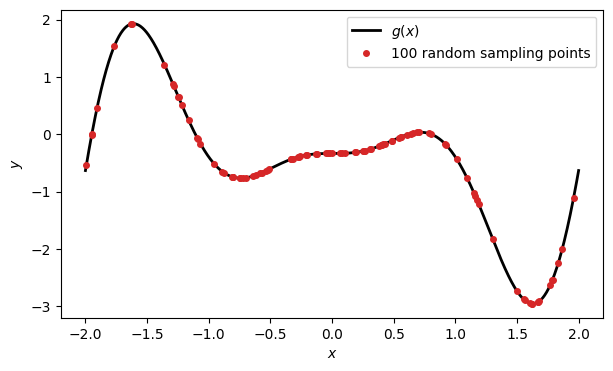

In [2]:
def g(x):
    """Target function from the Lecture Notes (Chapter 2)."""
    return x**2 * np.sin(np.pi * x) - 1.0 / (2.0 + np.cos(x))

K = 100
rng_data = np.random.default_rng(2026)
x_train = np.sort(rng_data.uniform(-2, 2, K))     # random, non-equidistant sampling points (sorted for convenience)
y_train = g(x_train)
x_plot = np.linspace(-2, 2, 1000)                 # dense grid, used only for plotting and for judging fits

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_plot, g(x_plot), "k", lw=2, label="$g(x)$")
ax.plot(x_train, y_train, "o", color="C3", ms=4, label=f"{K} random sampling points")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend()
plt.show()

<hr/>
## 2. Building blocks

### 2.1 One neuron
A single hidden neuron contributes $W^{(2)}\tanh(W^{(1)}x + b)$. The weight $W^{(1)}$ sets the **steepness**, the ratio $-b/W^{(1)}$ sets the **position** of the step,
and $W^{(2)}$ sets its **height**.

In the plotting code the labels are f-strings that contain LaTeX. Inside an f-string single braces `{w}` insert the value of a variable, so a literal brace, needed for the LaTeX
superscript `W^{(1)}`, is written twice: `f"$W^{{(1)}} = {w}$"` produces the text `$W^{(1)} = 0.5$`.

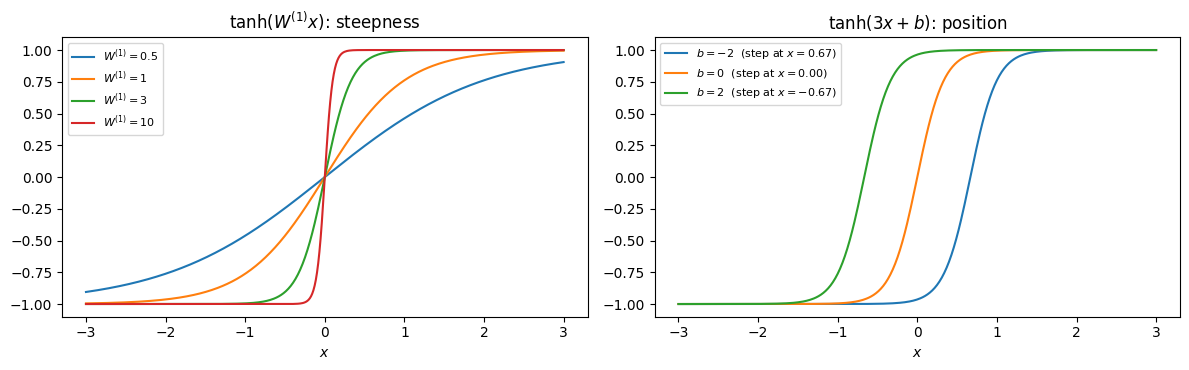

In [3]:
x = np.linspace(-3, 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for w in [0.5, 1, 3, 10]:
    axes[0].plot(x, np.tanh(w * x), label=f"$W^{{(1)}} = {w}$")
for b in [-2, 0, 2]:
    axes[1].plot(x, np.tanh(3 * x + b), label=f"$b = {b}$  (step at $x = {-b/3:.2f}$)")
axes[0].set_title(r"$\tanh(W^{(1)} x)$: steepness"); axes[1].set_title(r"$\tanh(3x + b)$: position")
for ax in axes:
    ax.set_xlabel("$x$"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### 2.2 Two neurons make a bump
The difference of two shifted steps is a localised bump:
$\tfrac12\big[\tanh(s(x - a)) - \tanh(s(x - c))\big] \approx 1$ for $a < x < c$ and $\approx 0$ elsewhere.
A sum of such bumps with suitable heights can follow any continuous curve — this is the intuition behind the UAT.
Each $\tanh$ goes from $-1$ to $+1$, i.e. changes by 2 across its step; the difference of two steps therefore has height 2, and the factor $\tfrac12$ normalises the bump to height 1.
The values $s = 8$, $a = -0.5$, $c = 1$ below are arbitrary illustration values.

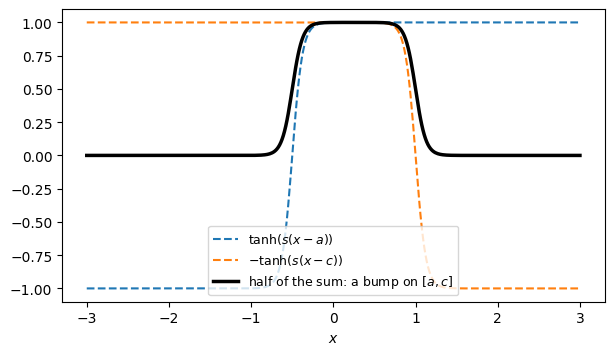

In [4]:
s, a, c = 8.0, -0.5, 1.0
step1, step2 = np.tanh(s * (x - a)), np.tanh(s * (x - c))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, step1, "--", label=r"$\tanh(s(x-a))$")
ax.plot(x, -step2, "--", label=r"$-\tanh(s(x-c))$")
ax.plot(x, 0.5 * (step1 - step2), "k", lw=2.5, label="half of the sum: a bump on $[a, c]$")
ax.set_xlabel("$x$"); ax.legend(fontsize=9)
plt.show()

<hr/>
## 3. A constructive approximation (no optimisation)

Divide $[-2,2]$ into $N$ intervals with nodes $x_0 < x_1 < \dots < x_N$. A staircase that jumps by $g(x_j) - g(x_{j-1})$ at the midpoint $m_j$ of each interval is
$$f_N(x) = g(x_0) + \sum_{j=1}^{N}\big[g(x_j) - g(x_{j-1})\big]\;\frac{1 + \tanh\big(s\,(x - m_j)\big)}{2}.$$
The function $\tfrac12\big(1+\tanh(s(x-m_j))\big)$ is a smooth step that goes from 0 (for $x \ll m_j$) to 1 (for $x \gg m_j$), so each term adds the jump $g(x_j)-g(x_{j-1})$ once $x$ has passed $m_j$.
This is a one-hidden-layer network with $N$ neurons (plus a constant). We chose all parameters by hand: $W^{(1)}_j = s$, $b_j = -s m_j$, $W^{(2)}_j = [g(x_j)-g(x_{j-1})]/2$.
The factor $\tfrac12$ in $W^{(2)}_j$ comes from $\tfrac12(1+\tanh z) = \tfrac12 + \tfrac12\tanh z$: each term is half a jump times $\tanh$, plus half a jump as a constant.
All these constants add up to the constant of the network, $g(x_0) + \tfrac12\sum_j[g(x_j)-g(x_{j-1})] = \tfrac12[g(x_0)+g(x_N)]$.
As $N\to\infty$ (with $s$ growing so that steps stay sharp) the error goes to zero — a constructive version of the theorem.

Two details of the code:
- **Steepness.** The intervals have width $h = 4/N$, and we take $s = 4N$, so $s\,h = 16$: each step rises from 0 to 1 within a small fraction of its interval, and the network is a genuine staircase.
  The factor 4 is arbitrary. Smaller factors make neighbouring steps overlap; the sum then becomes a smoother interpolation and is in fact somewhat more accurate
  (with factor 1 the error for $N \ge 64$ is about 2.5 times smaller), but the sharp version shows the construction better.
- **Broadcasting.** Indexing with `None` adds an axis of length 1: `x[:, None]` is a column of shape $(K, 1)$ and `mids[None, :]` a row of shape $(1, N)$.
  Their difference is broadcast to a $(K, N)$ table whose entry $(k, j)$ is $x_k - m_j$, i.e. neuron $j$ evaluated at point $k$. The product `hidden @ jumps` then sums over the neurons.

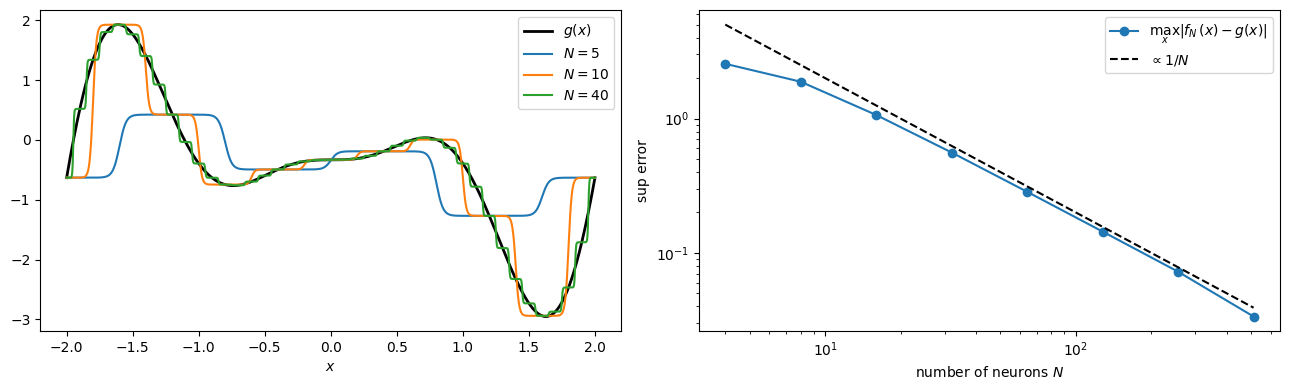

In [5]:
def staircase(x, N, steepness_factor=4.0):
    """Hand-built one-hidden-layer tanh network approximating g with N neurons."""
    nodes = np.linspace(-2, 2, N + 1)
    mids = 0.5 * (nodes[1:] + nodes[:-1])
    jumps = g(nodes[1:]) - g(nodes[:-1])
    s = steepness_factor * N                       # steps get sharper as intervals shrink
    hidden = 0.5 * (1 + np.tanh(s * (x[:, None] - mids[None, :])))   # shape (len(x), N)
    return g(nodes[0]) + hidden @ jumps

x_fine = np.linspace(-2, 2, 2000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(x_fine, g(x_fine), "k", lw=2, label="$g(x)$")
for N in [5, 10, 40]:
    axes[0].plot(x_fine, staircase(x_fine, N), label=f"$N = {N}$")
axes[0].set_xlabel("$x$"); axes[0].legend()

Ns = np.array([4, 8, 16, 32, 64, 128, 256, 512])
sup_err = [np.max(np.abs(staircase(x_fine, N) - g(x_fine))) for N in Ns]
axes[1].loglog(Ns, sup_err, "o-", label=r"$\max_x |f_N(x) - g(x)|$")
axes[1].loglog(Ns, 20 / Ns, "k--", label=r"$\propto 1/N$")   # guide line; the prefactor 20 only places it near the points
axes[1].set_xlabel("number of neurons $N$"); axes[1].set_ylabel("sup error"); axes[1].legend()
fig.tight_layout(); plt.show()

The construction works but is inefficient: the error decreases only like $1/N$, and it needs $g$ at equally spaced nodes of our choice.
The $1/N$ law follows from the shape of a staircase: within one interval it is (nearly) constant, while $g$ changes by up to $|g'|_{\max}\,h$ with $h = 4/N$.
The error is therefore at most about half of such a change, $\tfrac12|g'|_{\max}\cdot 4/N \approx 26/N$ for $|g'|_{\max}\approx 12.9$ on $[-2,2]$; the measured error is about $18/N$ for large $N$.
In practice the sampling points are given, and a minimiser has to choose all $3N$ parameters, including the positions of the steps. Section 7 shows that an optimised network with $N \approx 8$ neurons
is more accurate than the staircase with $N = 512$.
<hr/>
## 4. The loss function as a function of a parameter vector

Most minimisers (in particular `scipy.optimize.minimize`) work with a **flat vector** of parameters $\vec\theta\in\mathbb R^{3N}$.
We store $\vec\theta = (W^{(1)}_1,\dots,W^{(1)}_N,\; b_1,\dots,b_N,\; W^{(2)}_1,\dots,W^{(2)}_N)$ and unpack it inside the model.

**The model.** `np.outer(x, W1)` is the $K\times N$ matrix with entries $x_k W^{(1)}_i$. Adding the length-$N$ vector `b` adds $b_i$ to every entry of column $i$ (broadcasting),
so entry $(k, i)$ of the table is the argument of neuron $i$ at point $k$. Multiplying by `W2` with `@` sums the neurons with their output weights.

**The random initial parameters** are not arbitrary in their order of magnitude:
- $W^{(1)}_i, b_i \sim \mathcal N(0, 2^2)$. With $x\in[-2,2]$ a neuron $\tanh(W^{(1)}x+b)$ is a step at $x = -b/W^{(1)}$ of width about $1/|W^{(1)}|$.
  Values of order 2 give steps that are narrower than the interval and positions $-b/W^{(1)}$ that are of order 1, i.e. mostly inside the interval.
  Much smaller values give nearly linear neurons, much larger values give very sharp steps with vanishing slope almost everywhere.
- $W^{(2)}_i \sim \mathcal N(0, 1/N)$. The output is a sum of $N$ terms of random sign, so its variance is $N\cdot\mathrm{Var}(W^{(2)})$ times a number of order 1.
  With $\mathrm{Var}(W^{(2)}) = 1/N$ the initial $f(x)$ is of order 1, comparable to $g$, for every $N$ (the standard deviation of $W^{(2)}$ scales as $1/\sqrt N$).

$N = 10$ (30 parameters) is small enough for the gradient-free methods and the finite-difference gradients below to finish in seconds, and large enough for a good fit.

In [6]:
def unpack(theta):
    """Split the flat parameter vector into (W1, b, W2), each of length N."""
    N = theta.size // 3                         # // is integer division: 30 // 3 = 10 (an integer, usable as an index)
    return theta[:N], theta[N:2 * N], theta[2 * N:]

def model(theta, x):
    """f(x; theta) = sum_i W2_i tanh(W1_i x + b_i), evaluated for all x at once."""
    W1, b, W2 = unpack(theta)
    hidden = np.tanh(np.outer(x, W1) + b)       # shape (K, N): neuron i evaluated at point k
    return hidden @ W2                          # shape (K,)

def loss(theta, x=x_train, y=y_train):
    """Mean squared error on the training set."""
    return np.mean((model(theta, x) - y)**2)

def init_theta(N, seed):
    """Random initial parameters: input weights and biases ~ N(0, 2^2), output weights ~ N(0, 1/N)."""
    rng = np.random.default_rng(seed)
    # np.concatenate joins the three length-N arrays into one flat vector of length 3N
    return np.concatenate([rng.normal(0, 2, N), rng.normal(0, 2, N), rng.normal(0, 1, N) / np.sqrt(N)])

N = 10
theta0 = init_theta(N, seed=0)        # ONE common starting point for all minimisers below
print("number of parameters:", theta0.size, "  initial loss:", loss(theta0))

number of parameters: 30   initial loss: 1.0398383815103345


### 4.1 The gradient, derived by hand (backpropagation for one hidden layer)
With $a_{ki} = W^{(1)}_i x_k + b_i$, $h_{ki} = \tanh a_{ki}$, $f_k = \sum_i W^{(2)}_i h_{ki}$ and residuals $r_k = f_k - y_k$:
$$\frac{\partial\mathcal L}{\partial W^{(2)}_i} = \frac{2}{K}\sum_k r_k\,h_{ki},\qquad
\frac{\partial\mathcal L}{\partial b_i} = \frac{2}{K}\sum_k r_k\,W^{(2)}_i\,(1 - h_{ki}^2),\qquad
\frac{\partial\mathcal L}{\partial W^{(1)}_i} = \frac{2}{K}\sum_k r_k\,W^{(2)}_i\,(1 - h_{ki}^2)\,x_k .$$
The factors come from the chain rule: $\partial\mathcal L/\partial f_k = 2r_k/K$; then $\partial f_k/\partial W^{(2)}_i = h_{ki}$, $\partial f_k/\partial h_{ki} = W^{(2)}_i$,
$\partial h_{ki}/\partial a_{ki} = 1-h_{ki}^2$, and $\partial a_{ki}/\partial b_i = 1$, $\partial a_{ki}/\partial W^{(1)}_i = x_k$. Each parameter affects $\mathcal L$ through all $K$ points, hence the sums over $k$.
(We used $\tanh' = 1 - \tanh^2$.) This is the chain rule applied backwards through the network; autograd performs the same computation automatically.

A hand-derived gradient is easy to get wrong, so we compare it with the central difference $[\mathcal L(\vec\theta+\delta\vec e) - \mathcal L(\vec\theta-\delta\vec e)]/(2\delta)$ for every unit vector $\vec e$, with step $\delta$ (`eps` in the code).
Its truncation error is of order $\delta^2$ and its round-off error of order $10^{-16}/\delta$, so $\delta$ between about $10^{-4}$ and $10^{-7}$ gives differences of $10^{-9}$ or smaller;
we take $\delta = 10^{-6}$. The gradient components here are of order 1, so a mistake in one of the formulas would show up as a difference of order 1, not $10^{-10}$.

In [7]:
def grad(theta, x=x_train, y=y_train):
    """Analytic gradient of the MSE loss with respect to theta = (W1, b, W2)."""
    W1, b, W2 = unpack(theta)
    K = x.size
    h = np.tanh(np.outer(x, W1) + b)            # (K, N) hidden activations
    r = h @ W2 - y                              # (K,)   residuals
    dW2 = 2 / K * h.T @ r                       # (N,)   (2/K) sum_k r_k h_ki
    delta = 2 / K * r[:, None] * W2[None, :] * (1 - h**2)   # (K, N) dL/da_ki
    db = delta.sum(axis=0)                      # (N,)   sum over the points k
    dW1 = delta.T @ x                           # (N,)   sum_k delta_ki x_k
    return np.concatenate([dW1, db, dW2])

# Always check a hand-written gradient against finite differences before using it.
# The rows of np.eye(n) are the unit vectors e; each one perturbs a single parameter.
eps = 1e-6
fd = np.array([(loss(theta0 + eps * e) - loss(theta0 - eps * e)) / (2 * eps) for e in np.eye(theta0.size)])
print("max |analytic - finite difference| =", np.max(np.abs(grad(theta0) - fd)))

max |analytic - finite difference| = 2.181130831502287e-10


<hr/>
## 5. Minimisers in SciPy

`scipy.optimize.minimize(fun, x0, method=..., jac=...)` gives access to many classical algorithms. We compare two families:

| method | uses | idea |
|---|---|---|
| **Nelder–Mead** | only $\mathcal L$ | moves a simplex of $3N+1$ points by reflections/contractions |
| **Powell** | only $\mathcal L$ | successive 1D line minimisations along a set of directions |
| **CG** | $\mathcal L$, $\nabla\mathcal L$ | line searches along conjugate-gradient directions: each new direction is the gradient corrected so that it does not undo the progress along the previous directions |
| **BFGS** | $\mathcal L$, $\nabla\mathcal L$ | quasi-Newton: builds an approximation of the inverse Hessian from gradient history |
| **L-BFGS-B** | $\mathcal L$, $\nabla\mathcal L$ | BFGS with limited memory (stores the last few differences of parameters and gradients) — usable for many parameters; "-B": optional bounds on the parameters, not used here |

Two terms used in the table: a **simplex** in $n$ dimensions is a set of $n+1$ points (a triangle for $n = 2$, a tetrahedron for $n = 3$); Nelder–Mead compares $\mathcal L$ at its corners and moves
the worst corner. A **line search** (line minimisation) is a one-dimensional minimisation of $\mathcal L(\vec\theta + \alpha\vec d)$ over the step length $\alpha$ along a chosen direction $\vec d$.

To follow the progress we pass a `callback`, which SciPy calls after every iteration with the current $\vec\theta$.
We also count how many times $\mathcal L$ was evaluated (`nfev`) and, for the methods that use it, how many times the gradient was evaluated (`njev`);
with the analytic gradient one gradient costs about as much as a few evaluations of $\mathcal L$. `message` reports why the minimiser stopped.

Details of the code below:
- `minimize` returns an `OptimizeResult` object: `res.x` is the parameter vector at the end of the run, `res.fun` the loss there, `res.nfev`/`res.njev` the numbers of loss and gradient evaluations.
- Results of the gradient-free methods have no attribute `njev`. `getattr(obj, "name", default)` returns the attribute if it exists and `default` otherwise, so the code works for all methods.
- `maxiter = 5000`: the default limits differ between methods; with a common limit every method can stop on its own convergence criterion, except Nelder–Mead,
  which reaches the limit (with 20000 iterations it gets to $5\cdot10^{-2}$, still far from the other methods, at four times the cost). Each method has its own default stopping tolerance,
  so the final losses are not compared at equal accuracy; they show what each method delivers with its standard settings.

In [8]:
def run_scipy(method, use_grad, theta_start=theta0, maxiter=5000):
    """Minimise the loss with scipy; return a dict with the history and statistics."""
    history = [loss(theta_start)]
    callback = lambda th: history.append(loss(th))       # record loss after each iteration
    t0 = time.perf_counter()
    res = minimize(loss, theta_start, method=method,
                   jac=grad if use_grad else None,       # None -> scipy uses finite differences (if it needs a gradient)
                   callback=callback,
                   options={"maxiter": maxiter})
    return dict(theta=res.x, history=history, final_loss=res.fun, nfev=res.nfev,
                njev=getattr(res, "njev", 0), message=res.message, time=time.perf_counter() - t0)

scipy_runs = {
    "Nelder-Mead":           run_scipy("Nelder-Mead", use_grad=False),
    "Powell":                run_scipy("Powell", use_grad=False),
    "CG":                    run_scipy("CG", use_grad=True),
    "BFGS":                  run_scipy("BFGS", use_grad=True),
    "BFGS (finite-diff grad)": run_scipy("BFGS", use_grad=False),
    "L-BFGS-B":              run_scipy("L-BFGS-B", use_grad=True),
}
for name, r in scipy_runs.items():
    print(f"{name:25s} loss = {r['final_loss']:.2e}   nfev = {r['nfev']:6d}   njev = {r['njev']:5d}   time = {r['time']:.2f} s   ({r['message']})")

Nelder-Mead               loss = 8.06e-02   nfev =   5986   njev =     0   time = 0.32 s   (Maximum number of iterations has been exceeded.)
Powell                    loss = 4.95e-03   nfev =  28849   njev =     0   time = 0.80 s   (Optimization terminated successfully.)
CG                        loss = 2.69e-06   nfev =   3107   njev =  3107   time = 0.35 s   (Optimization terminated successfully.)
BFGS                      loss = 1.11e-06   nfev =    592   njev =   592   time = 0.09 s   (Optimization terminated successfully.)
BFGS (finite-diff grad)   loss = 2.19e-06   nfev =  16089   njev =   519   time = 0.48 s   (Optimization terminated successfully.)
L-BFGS-B                  loss = 1.34e-05   nfev =    703   njev =   703   time = 0.06 s   (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH)


Reading the table: BFGS reaches a loss of about $10^{-6}$ with about 600 evaluations, while Powell needs almost $3\cdot10^4$ evaluations and stops at a loss several thousand times larger,
and Nelder–Mead stops at the iteration limit with a loss of about 0.08.
The line *BFGS (finite-diff grad)* reaches a similar loss, but needs many more function evaluations, because every gradient costs $3N+1$ evaluations of $\mathcal L$.
With $10^6$ parameters this is not feasible; deep learning therefore relies on backpropagation.

### 5.1 Plain gradient descent with the hand-written gradient
$\vec\theta_{t+1} = \vec\theta_t - \eta\,\nabla\mathcal L(\vec\theta_t)$ with fixed learning rate $\eta$.

How large may $\eta$ be? Near a minimum $\mathcal L$ is approximately quadratic, and along the eigenvector of the Hessian with the largest eigenvalue $\lambda_{\max}$ one step multiplies the distance
to the minimum by $(1-\eta\lambda_{\max})$. The iteration is stable only if $|1-\eta\lambda_{\max}|<1$, i.e. $\eta < 2/\lambda_{\max}$; otherwise the parameters oscillate with growing amplitude.
For our start $\lambda_{\max}\approx 9$, so the limit is $\eta\approx 0.2$. We measured: $\eta = 0.5$ diverges within 10 steps, while $\eta$ up to $0.3$ does not diverge in 20000 steps: the parameters drift into a region where the landscape is flatter (at the end of the run with $\eta = 0.3$, $\lambda_{\max}\approx 6.7 \approx 2/0.3$), so the estimate from the starting point is only a rough guide.
The value $\eta = 0.05$ is a safe choice well below the limit, not an optimal one ($\eta = 0.1$ reaches a loss about 3 times lower here); Exercise 3 scans $\eta$ systematically.
Because each step is small, the loss decreases slowly along the flat directions of the landscape, hence the large number of steps.

In [9]:
eta, n_steps = 0.05, 20000
theta = theta0.copy()
gd_history = [loss(theta)]
t0 = time.perf_counter()
for t in range(n_steps):
    theta = theta - eta * grad(theta)
    gd_history.append(loss(theta))
gd_run = dict(theta=theta, history=gd_history, final_loss=gd_history[-1], nfev=n_steps, time=time.perf_counter() - t0)
print(f"gradient descent: loss = {gd_run['final_loss']:.2e} after {n_steps} steps")

gradient descent: loss = 3.70e-03 after 20000 steps


### 5.2 Comparison
Loss vs. iteration (left) and the resulting fits (right). An "iteration" means different things for different methods
(one simplex move, one line search, one gradient step), so the table of function and gradient evaluations above is also relevant.
What to look at: on the left, Powell decreases fastest during the first iterations (but each of its iterations costs many evaluations of $\mathcal L$); BFGS (with analytic or finite-difference gradient) and CG reach the lowest losses (about $10^{-6}$),
while L-BFGS-B stops about ten times higher with its default tolerance; gradient descent decreases slowly over $2\cdot10^4$ steps, and Nelder–Mead hardly moves during the first few hundred iterations. On the right, most fits lie on top of $g$; the Nelder–Mead fit is visibly wrong near the ends of the interval and around $x = 0$.

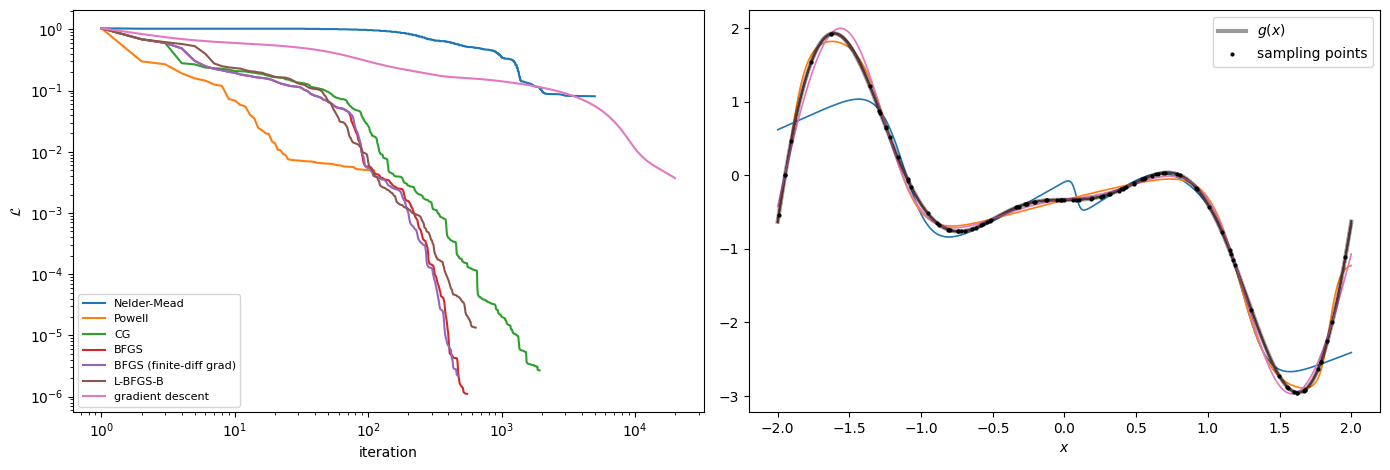

In [10]:
all_np = {**scipy_runs, "gradient descent": gd_run}     # new dict: all entries of scipy_runs plus one more
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, (name, r) in enumerate(all_np.items()):
    axes[0].loglog(np.arange(1, len(r["history"]) + 1), r["history"], color=f"C{i}", label=name)
    axes[1].plot(x_plot, model(r["theta"], x_plot), color=f"C{i}", lw=1.2)
axes[1].plot(x_plot, g(x_plot), "k", lw=3, alpha=0.4, label="$g(x)$")
axes[1].plot(x_train, y_train, "k.", ms=4, label="sampling points")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel(r"$\mathcal{L}$"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("$x$"); axes[1].legend()
fig.tight_layout(); plt.show()

<hr/>
## 6. The same problem in PyTorch: autograd + `torch.optim`

Here autograd computes the gradient, and we compare the optimisers used in deep learning
(see *The Zoo of Optimization Algorithms* in the Lecture Notes). We start from **the same** $\vec\theta_0$.
L-BFGS in PyTorch needs a `closure` — a function that recomputes the loss and gradient, because it evaluates them several times per step (line search).

Details of the code below:
- `getattr(torch.optim, "Adam")` is the same object as `torch.optim.Adam`: the optimiser class is selected from its name given as a string, so one function `run_torch` serves all optimisers.
- `**opt_kwargs` in the definition of a function collects all extra keyword arguments into a dictionary; `**kw` in a call unpacks a dictionary into keyword arguments,
  so `run_torch("SGD", 2000, **dict(lr=0.05))` is the same as `run_torch("SGD", 2000, lr=0.05)`.
- `opt.step(closure)` returns the loss computed by the (first) call of the closure, i.e. the loss **before** the update of this step. `.item()` turns the one-element tensor
  into a Python number, so the list `history` does not keep the computational graph in memory.

**Different learning rates.** With momentum $\beta = 0.9$ the steps accumulate along a steady slope to about $\mathrm{lr}/(1-\beta) = 10\,\mathrm{lr}$, so momentum needs a smaller lr than plain SGD.
RMSprop and Adam divide the gradient by a running average of its size, so for them lr is roughly the step length in parameter units, independent of the size of the gradient.
All these values were tuned by hand to give stable runs; they are typical, not optimal (Exercise 3 scans the learning rate).

**L-BFGS settings.** `max_iter = 20` is the number of inner quasi-Newton iterations per call of `step`, so 50 outer steps allow up to 1000 iterations (each with several evaluations of the loss in the line search), comparable in cost to the 2000 steps of the first-order methods.
The numbers of steps are kept small so that the cell runs in a few seconds; with 5000 steps the first-order methods reach lower losses (we measured Adam $9\cdot10^{-5}$, momentum $4\cdot10^{-3}$, RMSprop $10^{-2}$, SGD $6\cdot10^{-2}$).
`lr = 1` is the natural step length, because a quasi-Newton direction already has the scale of a Newton step. Without a line search PyTorch takes this fixed step,
which can increase the loss; with `line_search_fn="strong_wolfe"` the step length is adjusted at every iteration so that the loss decreases sufficiently (the Wolfe conditions).

In [11]:
xt, yt = torch.tensor(x_train), torch.tensor(y_train)

def model_torch(theta, x):
    """Same network as `model`, written with torch operations."""
    N = theta.numel() // 3
    W1, b, W2 = theta[:N], theta[N:2 * N], theta[2 * N:]
    return torch.tanh(x[:, None] * W1 + b) @ W2

def run_torch(opt_name, n_steps, **opt_kwargs):
    theta = torch.tensor(theta0, requires_grad=True)          # fresh copy of the common start
    opt = getattr(torch.optim, opt_name)([theta], **opt_kwargs)
    history = []

    def closure():                                            # forward + backward; used by every optimiser
        opt.zero_grad()
        L = torch.mean((model_torch(theta, xt) - yt)**2)
        L.backward()
        return L

    t0 = time.perf_counter()
    for _ in range(n_steps):
        L = opt.step(closure)                                 # SGD/Adam call closure once, LBFGS several times
        history.append(L.item())
    return dict(theta=theta.detach().numpy(), history=history, final_loss=history[-1],
                time=time.perf_counter() - t0)

torch_setups = {
    "SGD":             ("SGD",     2000, dict(lr=0.05)),
    "SGD + momentum":  ("SGD",     2000, dict(lr=0.02, momentum=0.9)),
    "RMSprop":         ("RMSprop", 2000, dict(lr=3e-3)),
    "Adam":            ("Adam",    2000, dict(lr=1e-2)),
    "L-BFGS (torch)":  ("LBFGS",     50, dict(lr=1, max_iter=20, line_search_fn="strong_wolfe")),
}
torch_runs = {name: run_torch(opt, n, **kw) for name, (opt, n, kw) in torch_setups.items()}
for name, r in torch_runs.items():
    print(f"{name:16s} loss = {r['final_loss']:.2e}   time = {r['time']:.2f} s")

SGD              loss = 1.12e-01   time = 0.53 s
SGD + momentum   loss = 2.43e-02   time = 0.51 s
RMSprop          loss = 3.54e-02   time = 0.54 s
Adam             loss = 4.29e-03   time = 0.58 s
L-BFGS (torch)   loss = 6.82e-06   time = 1.09 s


Loss versus optimiser step (left) and the error of the final fits on the dense grid (right). A perfect fit would give the horizontal line at zero in the right panel.
L-BFGS is close to this line everywhere. After 2000 steps Adam has errors of a few tenths, SGD, momentum and RMSprop of order 1 even inside the interval, and the largest errors (up to almost 2 for SGD)
are at the ends $x = \pm 2$, where the data constrain the fit only from one side.

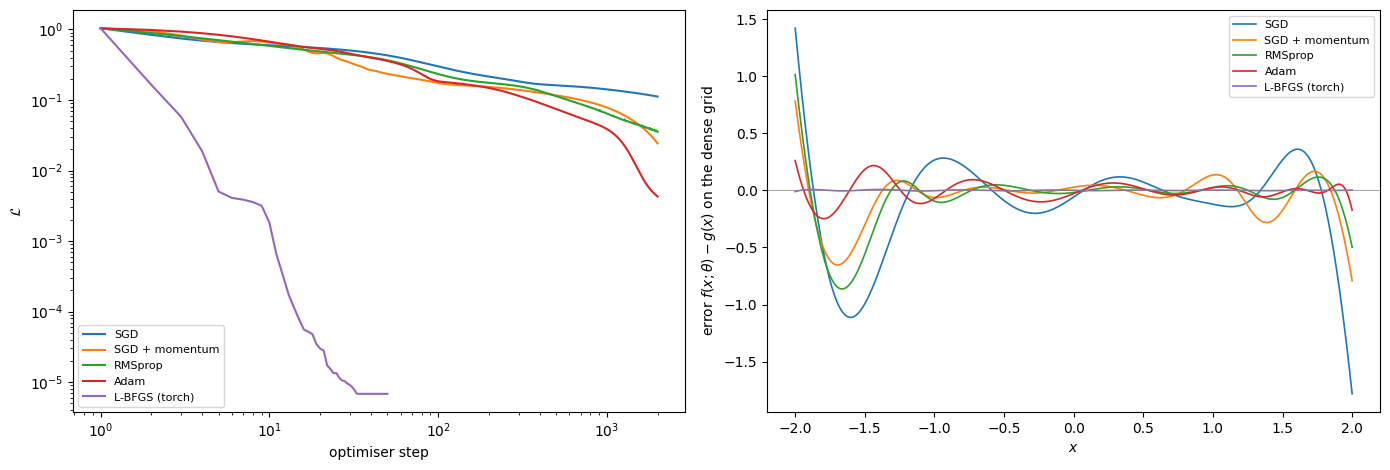

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, (name, r) in enumerate(torch_runs.items()):
    axes[0].loglog(np.arange(1, len(r["history"]) + 1), r["history"], color=f"C{i}", label=name)
    axes[1].plot(x_plot, model(r["theta"], x_plot) - g(x_plot), color=f"C{i}", lw=1.2, label=name)
axes[0].set_xlabel("optimiser step"); axes[0].set_ylabel(r"$\mathcal{L}$"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("$x$"); axes[1].set_ylabel(r"error $f(x;\theta) - g(x)$ on the dense grid"); axes[1].legend(fontsize=8)
axes[1].axhline(0, color="gray", lw=0.5)
fig.tight_layout(); plt.show()

### 6.1 Summary table
We collect all results in a `pandas` DataFrame and sort by the final loss.

In [13]:
rows = []
for name, r in scipy_runs.items():
    # dict.get(key, default) returns the value for key, or default if the key is absent: "analytic" for CG, BFGS, L-BFGS-B
    gradient = {"Nelder-Mead": "none", "Powell": "none", "BFGS (finite-diff grad)": "finite diff."}.get(name, "analytic")
    rows.append({"method": name, "library": "scipy", "gradient": gradient,
                 "final loss": r["final_loss"], "time [s]": r["time"]})
rows.append({"method": "gradient descent", "library": "numpy", "gradient": "analytic",
             "final loss": gd_run["final_loss"], "time [s]": gd_run["time"]})
for name, r in torch_runs.items():
    rows.append({"method": name, "library": "torch", "gradient": "autograd",
                 "final loss": r["final_loss"], "time [s]": r["time"]})

# sort the rows by the column "final loss"; reset_index(drop=True) renumbers the sorted rows 0, 1, 2, ...
summary = pd.DataFrame(rows).sort_values("final loss").reset_index(drop=True)
summary.style.format({"final loss": "{:.2e}", "time [s]": "{:.2f}"})

,method,library,gradient,final loss,time [s]
0,BFGS,scipy,analytic,1.11e-06,0.09
1,BFGS (finite-diff grad),scipy,finite diff.,2.19e-06,0.48
2,CG,scipy,analytic,2.69e-06,0.35
3,L-BFGS (torch),torch,autograd,6.82e-06,1.09
4,L-BFGS-B,scipy,analytic,1.34e-05,0.06
5,gradient descent,numpy,analytic,3.70e-03,0.89
6,Adam,torch,autograd,4.29e-03,0.58
7,Powell,scipy,none,4.95e-03,0.80
8,SGD + momentum,torch,autograd,2.43e-02,0.51
9,RMSprop,torch,autograd,3.54e-02,0.54


**Observations** (the exact numbers depend on the random start and on the hyperparameters):
- Gradient-free methods (Nelder–Mead, Powell) need many function evaluations already for 30 parameters; Nelder–Mead stopped at the iteration limit without converging (see its message above).
- Methods that use curvature information (BFGS, L-BFGS), which build an approximation of the curvature (the Hessian) from the history of gradients, or conjugate directions (CG) are the most accurate for this small, smooth, full-batch problem.
- First-order methods (SGD, momentum, RMSprop, Adam) are slower to converge here, but they are the only ones that remain practical for
  millions of parameters and **mini-batches** of data (at every step the gradient is computed from a random subset of the data, which makes it noisy), which is the situation in deep learning.
- Every method has hyperparameters (learning rate, momentum, number of steps); with other values the ranking can change (Exercise 3).
<hr/>
## 7. The UAT numerically: loss vs. number of neurons

For each $N$ we run BFGS from a few random starting points and keep the best result.

- **Restarts.** The landscape is non-convex (Section 9), so a single run can end in a poor minimum. Three starts per $N$ (seeds 0, 1, 2) are a compromise between cost and the chance
  of missing a good minimum; any small number (3–10) is reasonable.
- **`gtol`.** BFGS stops when the largest component of the gradient falls below `gtol` (default $10^{-5}$), or after `maxiter` iterations. With the default, the run for $N = 8$ stops
  at a loss of about $10^{-6}$, although much lower losses exist: near such a small minimum the gradient is already tiny. We therefore set `gtol = 1e-8`.
- **`maxiter`.** To keep the cell fast we allow at most 1000 iterations, and for $N \ge 6$ the runs stop at this limit. The losses for $N \ge 6$ (of order $10^{-7}$) are therefore set
  by the iteration budget, not by $N$. With `max_iter = 5000` (about four times longer) we measured $1.6\cdot10^{-9}$ for $N = 8$ and $10^{-10}$ for $N = 12$.

In [14]:
Ns = [1, 2, 3, 4, 6, 8, 12]
max_iter = 1000          # kept small so that the cell runs in a few seconds; 5000 gives lower losses for N >= 6
best_loss, best_theta = {}, {}
t0 = time.perf_counter()
for N in Ns:
    results = [minimize(loss, init_theta(N, seed), jac=grad, method="BFGS",
                        options={"maxiter": max_iter, "gtol": 1e-8}) for seed in range(3)]
    best = min(results, key=lambda r: r.fun)      # the result with the smallest r.fun (final loss)
    best_loss[N], best_theta[N] = best.fun, best.x
    print(f"N = {N:2d}   ({3*N:2d} parameters)   best loss = {best.fun:.2e}")
print(f"total time {time.perf_counter() - t0:.1f} s")

N =  1   ( 3 parameters)   best loss = 5.15e-01
N =  2   ( 6 parameters)   best loss = 2.20e-01
N =  3   ( 9 parameters)   best loss = 8.78e-02


N =  4   (12 parameters)   best loss = 2.91e-03


N =  6   (18 parameters)   best loss = 4.06e-07


N =  8   (24 parameters)   best loss = 7.10e-07


N = 12   (36 parameters)   best loss = 6.02e-08
total time 2.1 s


Best loss versus the number of neurons (left), and the fits for $N = 2, 3, 4, 8$ (right):

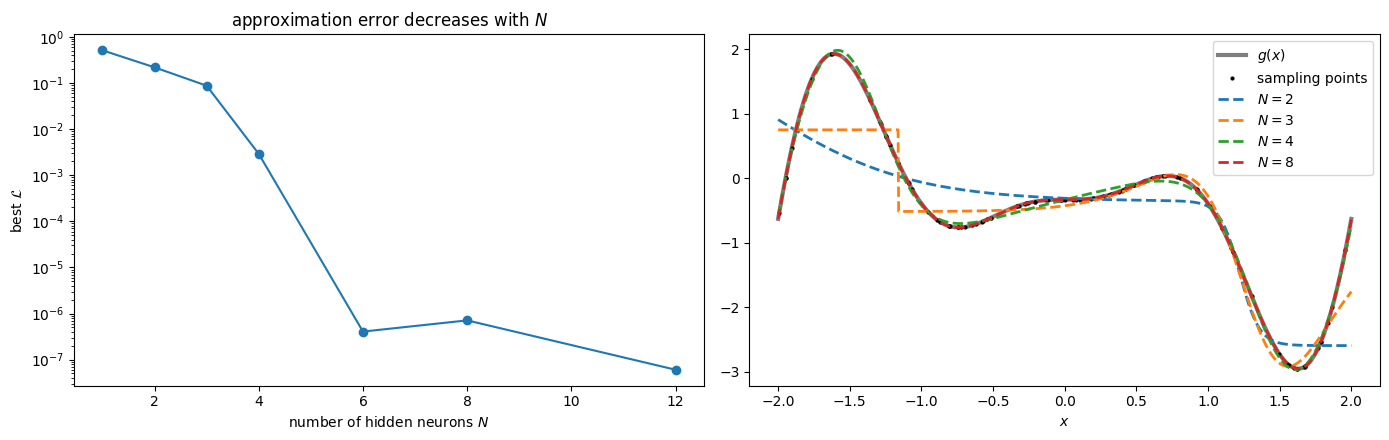

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].semilogy(Ns, [best_loss[N] for N in Ns], "o-")
axes[0].set_xlabel("number of hidden neurons $N$"); axes[0].set_ylabel(r"best $\mathcal{L}$")
axes[0].set_title("best loss vs. N (1000 BFGS iterations)")

axes[1].plot(x_plot, g(x_plot), "k", lw=3, alpha=0.5, label="$g(x)$")
axes[1].plot(x_train, y_train, "k.", ms=4, label="sampling points")
for N in [2, 3, 4, 8]:
    axes[1].plot(x_plot, model(best_theta[N], x_plot), "--", lw=2, label=f"$N = {N}$")
axes[1].set_xlabel("$x$"); axes[1].legend()
fig.tight_layout(); plt.show()

Compare with Fig. 2.3 of the Lecture Notes ($N = 2, 3, 4$). Already $N = 6$ to $8$ neurons give a mean squared error below $10^{-6}$ on the training points (and of order $10^{-9}$ with more iterations); the small rise from $N = 6$ to $N = 8$ is due to the iteration limit.
The maximal error on the dense grid is compared with the hand-made staircase below.

In [16]:
sup_net = np.max(np.abs(model(best_theta[8], x_plot) - g(x_plot)))
sup_stair = np.max(np.abs(staircase(x_plot, 512) - g(x_plot)))
print(f"max |f - g| on the dense grid:  optimised network N = 8: {sup_net:.1e},   staircase N = 512: {sup_stair:.1e}")

max |f - g| on the dense grid:  optimised network N = 8: 8.0e-03,   staircase N = 512: 3.4e-02


<hr/>
## 8. Building approximators for other functions

We now collect everything into one tool that builds the approximator
$$f(x;\vec W^{(1)},\vec b,\vec W^{(2)}) = \sum_{i=1}^{N} W^{(2)}_i\,\sigma\big(W^{(1)}_i x + b_i\big) + c$$
for **any** target $g(x)$ on an interval $[x_\min, x_\max]$, with a chosen number of hidden nodes $N$ (we use 'node' and 'neuron' interchangeably), activation $\sigma$, number of sampling points $K$ and minimiser.
We add an output bias $c$: for activations that are not odd, i.e. do not satisfy $\sigma(-z) = -\sigma(z)$ (sigmoid, ReLU, ...), it is needed to shift the output; for $\tanh$ it changes little.

The steps inside `fit_uat` are exactly the ones from the lecture:
1. **data** — sample $K$ points $x_k$ in the interval and compute $y_k = g(x_k)$;
2. **model** — parameters $\vec\theta = (\vec W^{(1)}, \vec b, \vec W^{(2)}, c)$, initialised randomly;
3. **loss** — $\mathcal L(\vec\theta) = \frac1K\sum_k \big(y_k - f(x_k;\vec\theta)\big)^2$;
4. **minimisation** — repeat: compute $\mathcal L$, compute $\nabla_{\vec\theta}\mathcal L$ by autograd, update $\vec\theta$;
5. since the landscape is non-convex, optionally repeat from a few random starts (`n_restarts`) and keep the best result.

Choices made inside `fit_uat`, and why:
- **Rescaling of the input.** $x$ is mapped linearly to $[-1, 1]$ before entering the network. The random initial steps have positions $-b_i/W^{(1)}_i$ of order 1 and widths $1/|W^{(1)}_i|$
  of order $1/3$, so they cover $[-1,1]$ well. On an interval far from this scale the same initialisation fails: for $g$ shifted to $[100, 104]$ (8 nodes) the loss stays at 1.4,
  which is the variance of the data (no fit at all, every $\tanh$ is saturated), while with rescaling it reaches $3\cdot10^{-6}$; on $[-0.02, 0.02]$ the numbers are 0.13 and $2\cdot10^{-5}$.
  For the intervals used below, all of width 2–6 around 0, rescaling makes little difference, but it costs nothing. The output $y$ is not rescaled; the targets below are of order 1.
- **Initial weights.** $W^{(1)}_i, b_i \sim \mathcal N(0, 3^2)$ and $W^{(2)}_i\sim\mathcal N(0, 1/N)$ (Section 4). The value 3 is arbitrary. We tested standard deviations 1, 3, 5 and 10 with 8 nodes:
  for the smooth targets all of them give small final losses, with no systematic trend; for the sawtooth the final loss ranges from $10^{-4}$ to $10^{-1}$ and depends mainly
  on which minimum the run happens to reach (Section 9), not on this value.
- **Output bias** $c$ starts at the mean of the data, so the nodes only have to represent the deviations from the mean. Starting from $c = 0$ also works.
- **Default steps and learning rates** follow Section 6: L-BFGS needs some tens of outer steps with lr $= 1$, first-order methods need thousands of steps with a small lr.
  The defaults (30 L-BFGS steps of up to 20 inner iterations each, 2000 Adam/SGD steps, a single start) are kept small so that every figure below takes only a few seconds;
  larger values (e.g. `n_steps=100, n_restarts=5`) give lower losses for the larger $N$, at a correspondingly higher cost.

In [17]:
import torch.nn.functional as F    # PyTorch module with activation functions written as plain functions, e.g. F.elu(z)

# Activation functions from the lecture slide
ACTIVATIONS = {
    "sigmoid":   torch.sigmoid,
    "tanh":      torch.tanh,
    "ReLU":      torch.relu,
    "LeakyReLU": lambda z: F.leaky_relu(z, negative_slope=0.1),
    "ELU":       F.elu,
}

def fit_uat(g, x_range, N, K=30, activation="tanh", optimizer="LBFGS",
            n_steps=None, lr=None, n_restarts=1, sampling="random", seed=0):
    """
    Fit f(x) = sum_i W2_i * sigma(W1_i * x + b_i) + c  to the function g on the interval x_range.

    g          : function of a NumPy array (the target)
    x_range    : (x_min, x_max)
    N          : number of nodes in the single hidden layer
    K          : number of sampling (training) points
    activation : key of ACTIVATIONS
    optimizer  : "LBFGS", "Adam" or "SGD"
    n_restarts : number of random initialisations; the best one is returned
    sampling   : "random" (uniformly random points) or "grid" (equally spaced points)
    Returns a dict with the fitted predictor, the data, the final loss and the loss history.
    """
    sigma = ACTIVATIONS[activation]
    x_min, x_max = x_range
    rng = np.random.default_rng(seed)

    # ---- 1. data -------------------------------------------------------------------------
    if sampling == "random":
        x_data = np.sort(rng.uniform(x_min, x_max, K))
    else:
        x_data = np.linspace(x_min, x_max, K)
    y_data = g(x_data)
    to_unit = lambda x: 2 * (x - x_min) / (x_max - x_min) - 1      # rescale input to [-1, 1]
    xt, yt = torch.tensor(to_unit(x_data)), torch.tensor(y_data)

    # default number of steps and learning rate for each optimiser
    defaults = {"LBFGS": (30, 1.0), "Adam": (2000, 1e-2), "SGD": (2000, 1e-2)}
    # `a or b` gives b when a is None (or 0): the default is used only when no value was passed
    n_steps = n_steps or defaults[optimizer][0]
    lr = lr or defaults[optimizer][1]

    best = None
    for restart in range(n_restarts):
        torch.manual_seed(seed + restart)
        # ---- 2. model parameters (random initialisation) -----------------------------
        W1 = (3 * torch.randn(N)).requires_grad_()               # steepness of each node
        b = (3 * torch.randn(N)).requires_grad_()                # position of each node
        W2 = (torch.randn(N) / np.sqrt(N)).requires_grad_()      # height of each node
        c = torch.tensor([float(y_data.mean())], requires_grad=True)  # output bias
        params = [W1, b, W2, c]

        def f(x):                                                # the approximator f(x; theta)
            return sigma(x[:, None] * W1 + b) @ W2 + c

        # ---- 3. loss -----------------------------------------------------------------
        # closure uses opt, which is created only further down: Python looks up the name opt when closure is CALLED
        # (inside opt.step), not when it is defined, and by then opt exists.
        def closure():
            opt.zero_grad()
            L = torch.mean((yt - f(xt))**2)
            L.backward()                                         # gradient by autograd
            return L

        # ---- 4. minimisation ---------------------------------------------------------
        if optimizer == "LBFGS":
            opt = torch.optim.LBFGS(params, lr=lr, max_iter=20, line_search_fn="strong_wolfe")
        else:
            opt = getattr(torch.optim, optimizer)(params, lr=lr)
        history = []
        for step in range(n_steps):
            L = opt.step(closure)
            history.append(L.item())
            if not np.isfinite(history[-1]):                     # stop a diverging run
                break

        # ---- 5. keep the best restart ------------------------------------------------
        # keep this restart if it is the first one, if the best so far diverged (nan), or if it is better
        if best is None or not np.isfinite(best["loss"]) or history[-1] < best["loss"]:
            # detach().clone(): an independent copy outside the autograd graph, not changed by later restarts.
            # The default argument frozen=frozen is evaluated when predict is defined, so predict keeps the
            # parameters of THIS restart (a direct reference to W1, b, ... would see the names of the last restart).
            frozen = [p.detach().clone() for p in params]
            def predict(x, frozen=frozen):
                W1_, b_, W2_, c_ = frozen
                return (sigma(torch.tensor(to_unit(np.asarray(x)))[:, None] * W1_ + b_) @ W2_ + c_).numpy()
            best = dict(predict=predict, loss=history[-1], history=history,
                        x_data=x_data, y_data=y_data, N=N, activation=activation)
    return best

And a plotting function that reproduces the figure from the lecture slide: the target $g(x)$, the sampling points, and the approximations
for several $N$; on the right, the loss during minimisation.

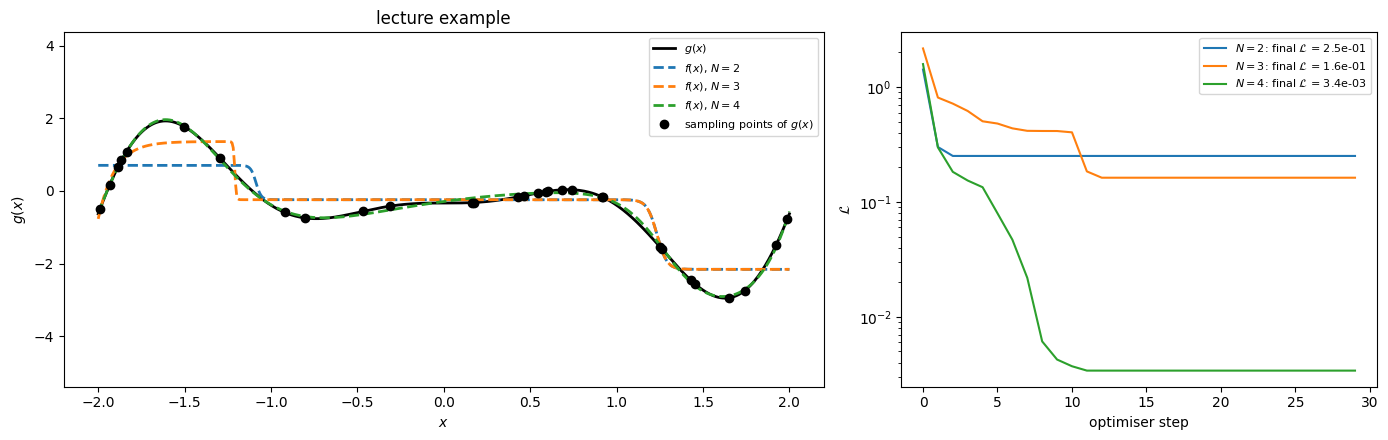

In [18]:
def plot_approximations(g, x_range, N_list, title="", **fit_kwargs):
    """Fit and plot f(x) for every N in N_list (as on the lecture slide), plus the loss curves."""
    x_plot = np.linspace(*x_range, 600)          # *x_range unpacks the pair: same as np.linspace(x_range[0], x_range[1], 600)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})   # left panel 1.6 times wider
    axes[0].plot(x_plot, g(x_plot), "k", lw=2, label="$g(x)$")
    for i, N in enumerate(N_list):
        res = fit_uat(g, x_range, N, **fit_kwargs)
        axes[0].plot(x_plot, res["predict"](x_plot), "--", lw=2, color=f"C{i}",
                     label=f"$f(x)$, $N = {N}$")
        axes[1].semilogy(res["history"], color=f"C{i}", label=f"$N = {N}$: final $\\mathcal{{L}}$ = {res['loss']:.1e}")
    axes[0].plot(res["x_data"], res["y_data"], "o", color="k", ms=6, label="sampling points of $g(x)$")
    # limit the vertical range: between sampling points a fit can make very large excursions, which would hide everything else
    g_min, g_max = g(x_plot).min(), g(x_plot).max()
    span = g_max - g_min
    axes[0].set_ylim(g_min - 0.5 * span, g_max + 0.5 * span)
    axes[0].set_xlabel("$x$"); axes[0].set_ylabel("$g(x)$"); axes[0].set_title(title)
    axes[0].legend(fontsize=8)
    axes[1].set_xlabel("optimiser step"); axes[1].set_ylabel(r"$\mathcal{L}$"); axes[1].legend(fontsize=8)
    fig.tight_layout(); plt.show()

# The example from the slide: g(x) on [-2, 2], K = 30 random sampling points, N = 2, 3, 4
plot_approximations(g, (-2, 2), N_list=[2, 3, 4], K=30, title="lecture example")

This is the situation of the lecture slide. With $N = 2$ and $N = 3$ the fits are made of a few steep steps, and their loss curves become flat after a few steps:
the minimiser has stopped in a minimum and more steps do not help (with `n_steps=100` the final losses for this seed are unchanged). The result depends on the starting point:
for $N = 3$ the seeds 0–5 give final losses between $9\cdot10^{-3}$ and $5\cdot10^{-1}$. With $N = 4$ the fit follows $g$ closely.

### 8.1 A gallery of harder targets
Some functions are harder than others. The number of nodes needed depends on how many "features" (bumps, kinks, steps) the function has
on the interval, and how sharp they are. Examples:
- a Gaussian wave packet $e^{-x^2}\cos(8x)$: many oscillations;
- $|x|$: a kink (not differentiable at 0);
- a smoothed step $\tanh(30x)$: very steep;
- a sawtooth: several jumps;
- the Lennard-Jones potential $4(r^{-12} - r^{-6})$: steep wall plus shallow minimum (in its panel the horizontal axis is the distance $r$);
- the ground state of the double well $V = \tfrac12x^2 + \kappa e^{-x^2/2}$ ($\kappa = 6$, units $\hbar = m = 1$). It is computed by discretising $H = -\tfrac12\, d^2/dx^2 + V$ with the three-point stencil on 400 equally spaced points in $[-6, 6]$ and diagonalising the resulting matrix.

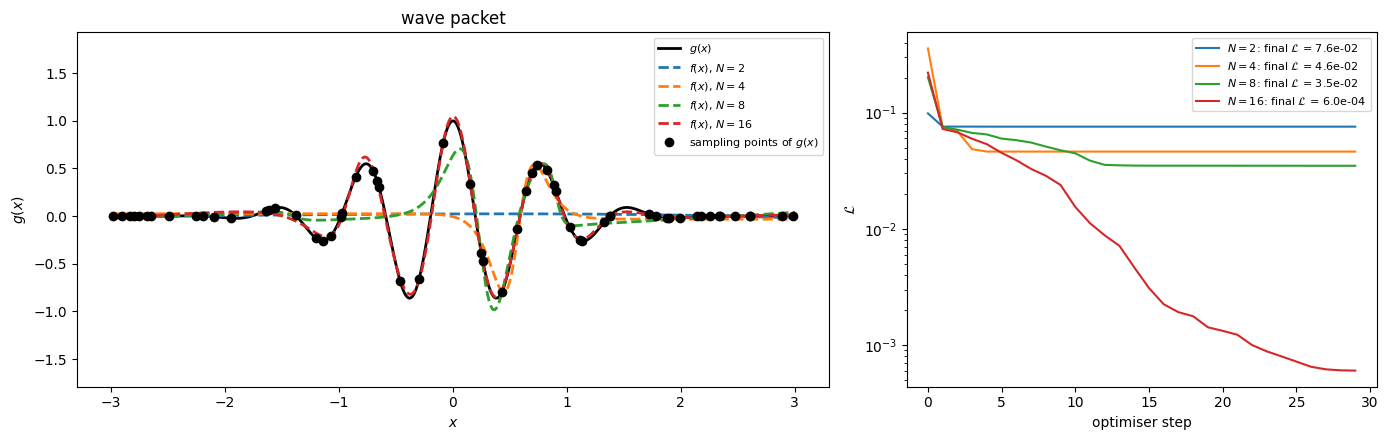

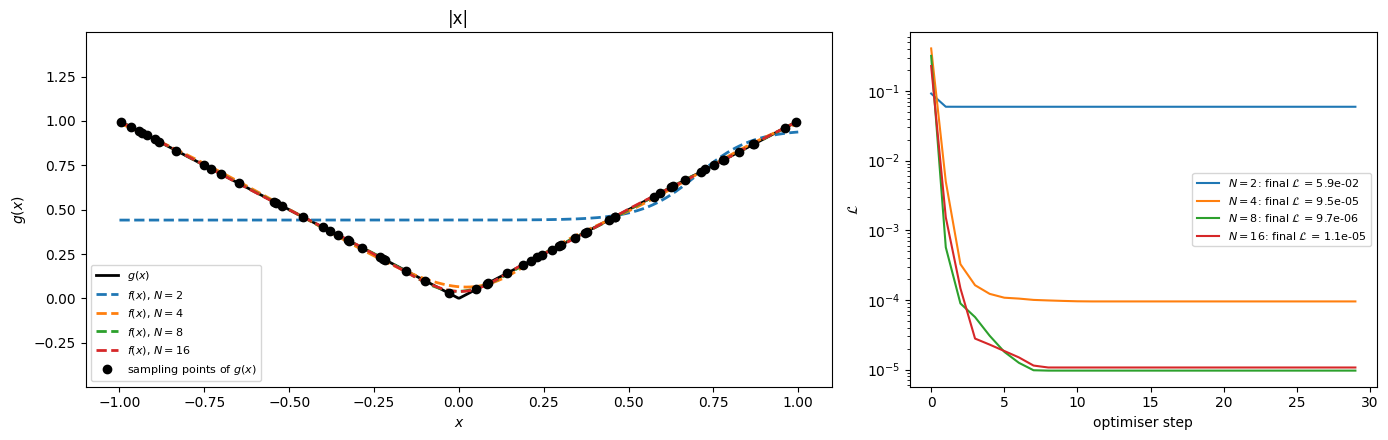

In [19]:
def double_well_ground_state(x, kappa=6.0):
    """Ground-state wavefunction of V = x^2/2 + kappa exp(-x^2/2), interpolated onto x."""
    grid = np.linspace(-6, 6, 400); dx = grid[1] - grid[0]
    H = (-0.5 / dx**2 * (np.diag(np.ones(399), 1) - 2 * np.eye(400) + np.diag(np.ones(399), -1))
         + np.diag(0.5 * grid**2 + kappa * np.exp(-grid**2 / 2)))
    psi0 = np.linalg.eigh(H)[1][:, 0]
    # eigh normalises sum(psi0**2) = 1; dividing by sqrt(dx) gives sum(psi0**2) * dx = 1, the discrete form of
    # the integral normalisation. abs() removes the arbitrary overall sign (the ground state has no nodes).
    psi0 = np.abs(psi0) / np.sqrt(dx)
    return np.interp(x, grid, psi0)          # linear interpolation of the grid values psi0 at the points x

TARGETS = {
    # name: (function, interval)
    "lecture g(x)":            (g, (-2, 2)),
    "wave packet":             (lambda x: np.exp(-x**2) * np.cos(8 * x), (-3, 3)),
    "|x|":                     (np.abs, (-1, 1)),
    "steep step tanh(30x)":    (lambda x: np.tanh(30 * x), (-1, 1)),
    "sawtooth":                (lambda x: 2 * (x - np.floor(x + 0.5)), (-2, 2)),   # x - floor(x + 1/2): signed distance to the nearest integer, in [-1/2, 1/2)
    "Lennard-Jones":           (lambda r: 4 * (r**-12 - r**-6), (0.95, 3.0)),
    "double-well ground state": (double_well_ground_state, (-4, 4)),
}

# K = 60 sampling points (instead of 30): the harder targets need more points to resolve their oscillations and jumps.
# For N = 16 the network has 49 parameters (3N + 1 with the output bias c), comparable to K; experiment 3 of Section 8.2
# shows what happens when K is smaller than the number of parameters.
# The intervals contain the region where each function has its features; their exact limits are arbitrary.
for name in ["wave packet", "|x|"]:
    func, interval = TARGETS[name]
    plot_approximations(func, interval, N_list=[2, 4, 8, 16], K=60, title=name)

The sawtooth and the Lennard-Jones potential, with the same settings:

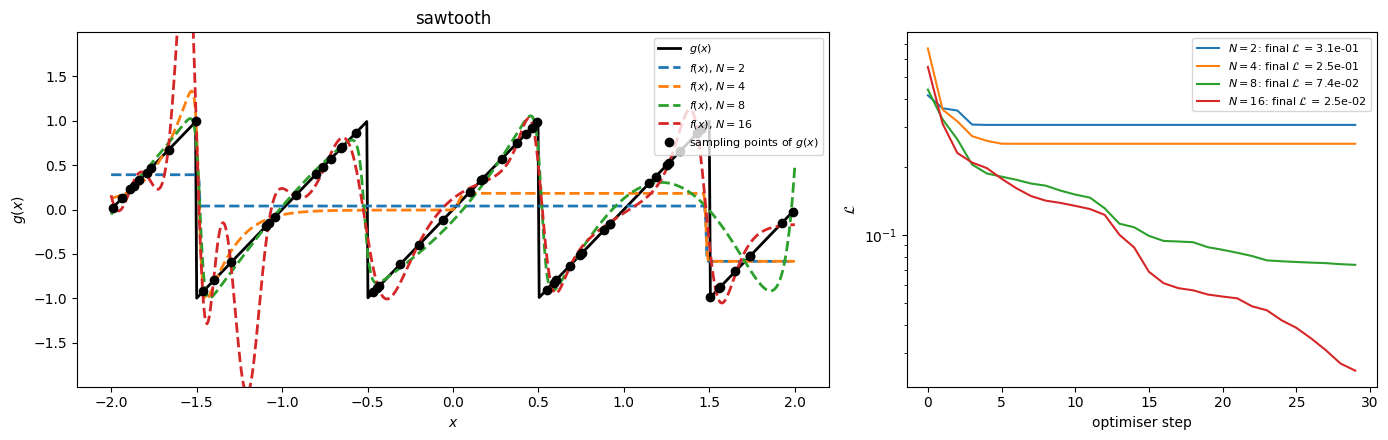

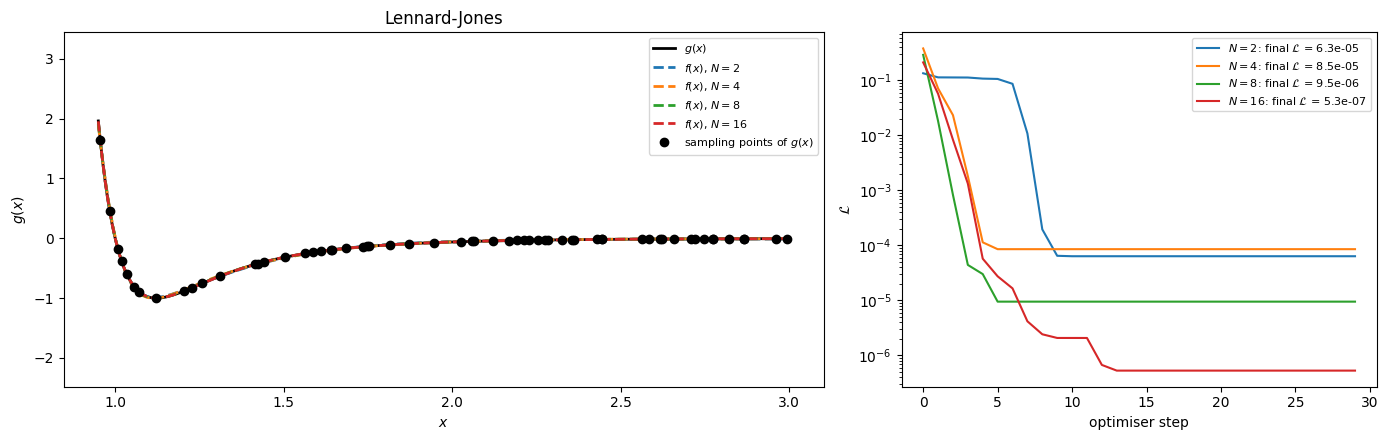

In [20]:
for name in ["sawtooth", "Lennard-Jones"]:
    func, interval = TARGETS[name]
    plot_approximations(func, interval, N_list=[2, 4, 8, 16], K=60, title=name)

Observations:
- the wave packet has 9 maxima and minima of visible size; $N = 8$ still misses several of them, while $N = 16$ (about two nodes per extremum) follows all of them;
- for $|x|$ a ReLU network would need only two nodes ($|x| = \mathrm{ReLU}(x) + \mathrm{ReLU}(-x)$), while $\tanh$ needs several — the choice of $\sigma$ matters;
- jumps (sawtooth) are approximated by very steep $\tanh$ nodes; between sampling points the fit can do anything. For $N = 16$ the loss is still decreasing after the
  30 default L-BFGS steps; `n_steps=100` gives a much better fit;
- on $[0.95, 3]$ the Lennard-Jones potential varies only between $-1$ and $2$ and is fitted well already with a few nodes; closer to $r = 0.9$ the wall would
  grow much faster and the fit would become harder.

### 8.2 Experiments with the settings
Change the settings in the cell below and run it. In Colab the comments `# @param` turn into a form with drop-down lists and sliders on the right side of the cell; outside Colab they are ordinary comments and the values are changed by editing the lines.

Suggested experiments:
1. For each target find the smallest $N$ for which the fit looks good. How does it depend on the target?
2. Compare `tanh` with `ReLU` for `|x|` and for the `wave packet`.
3. Take `K = 8` sampling points and `N = 16` nodes. Does a small loss mean a good approximation of $g$ between the points?
4. Switch the optimiser to `SGD` or `Adam` and compare the loss curves with `LBFGS`.
5. Add a new target function to the `TARGETS` dictionary, e.g. in a new cell `TARGETS["my function"] = (lambda x: x * np.sin(3 * x), (-2, 2))`,
   and set `target_name = "my function"` by editing the line (the drop-down list shows only the names written in the `# @param` comment).

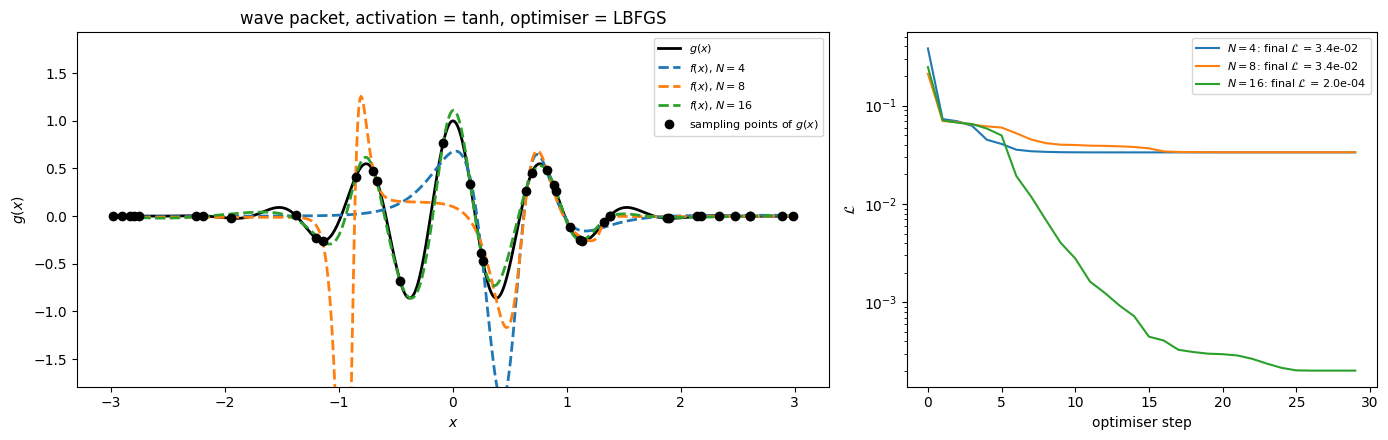

In [21]:
target_name = "wave packet"   # @param ["lecture g(x)", "wave packet", "|x|", "steep step tanh(30x)", "sawtooth", "Lennard-Jones", "double-well ground state"]
N1 = 4                        # @param {type:"slider", min:1, max:64, step:1}
N2 = 8                        # @param {type:"slider", min:1, max:64, step:1}
N3 = 16                       # @param {type:"slider", min:1, max:64, step:1}
activation = "tanh"           # @param ["tanh", "sigmoid", "ReLU", "LeakyReLU", "ELU"]
K = 40                        # @param {type:"slider", min:4, max:200, step:1}
sampling = "random"           # @param ["random", "grid"]
optimizer = "LBFGS"           # @param ["LBFGS", "Adam", "SGD"]
seed = 0                      # @param {type:"integer"}

func, interval = TARGETS[target_name]
plot_approximations(func, interval, N_list=[N1, N2, N3], K=K, activation=activation,
                    optimizer=optimizer, sampling=sampling, seed=seed,
                    title=f"{target_name}, activation = {activation}, optimiser = {optimizer}")

<hr/>
## 9. A non-convex landscape: different starts, different minima

$\mathcal L(\vec\theta)$ is not convex. Running the same minimiser (BFGS) from 10 random starting points gives a whole distribution of final losses.
We use $N = 6$: small enough for 10 BFGS runs (at most 1000 iterations each) to take only seconds, and large enough for the final losses to spread over several orders of magnitude (from about $10^{-6}$ to $3\cdot10^{-3}$ here).

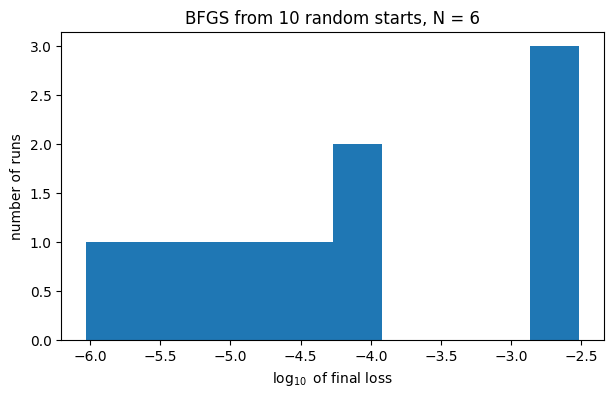

In [22]:
N = 6
finals, thetas = [], []
for seed in range(10):       # 10 starts keep the cell fast; 30 or more give a smoother histogram
    # seeds 100..109: starting points different from those of Section 7 (the value 100 is arbitrary)
    r = minimize(loss, init_theta(N, seed=100 + seed), jac=grad, method="BFGS", options={"maxiter": 1000, "gtol": 1e-8})
    finals.append(r.fun); thetas.append(r.x)
finals = np.array(finals)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.log10(finals), bins=10)
ax.set_xlabel(r"$\log_{10}$ of final loss"); ax.set_ylabel("number of runs")
ax.set_title(f"BFGS from {len(finals)} random starts, N = {N}")
plt.show()

Take the best solution $\vec\theta_A$ and a worse one $\vec\theta_B$, and evaluate the loss along the straight line between them,
$\mathcal L\big((1-t)\vec\theta_A + t\vec\theta_B\big)$. If the landscape were convex, this curve could not have a maximum between the two minima.

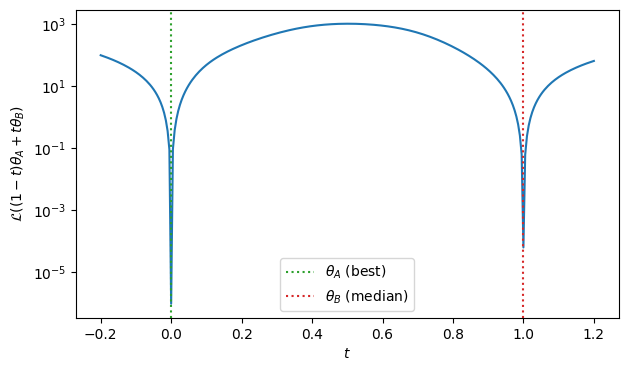

In [23]:
order = np.argsort(finals)
theta_A, theta_B = thetas[order[0]], thetas[order[len(order) // 2]]   # best and median run
ts = np.linspace(-0.2, 1.2, 281)          # step 0.005: the grid contains t = 0 and t = 1 exactly
# t < 0 and t > 1 are included to show that the loss also rises on the outer side of each minimum
path_loss = [loss((1 - t) * theta_A + t * theta_B) for t in ts]

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(ts, path_loss)
ax.axvline(0, color="C2", ls=":", label=r"$\theta_A$ (best)")
ax.axvline(1, color="C3", ls=":", label=r"$\theta_B$ (median)")
ax.set_xlabel("$t$"); ax.set_ylabel(r"$\mathcal{L}((1-t)\theta_A + t\theta_B)$"); ax.legend()
plt.show()

There is a barrier between the two minima. The valleys around the minima are very narrow (the parameters have large values, so a small relative change of
$\vec\theta$ changes $f$ strongly); this is why the curve must be evaluated exactly at $t=0$ and $t=1$ to show the minimal losses. Part of the multiplicity is trivial: permuting the $N$ neurons, or flipping the signs
$(W^{(1)}_i, b_i, W^{(2)}_i)\to(-W^{(1)}_i, -b_i, -W^{(2)}_i)$ (since $\tanh$ is odd), does not change $f$.
So a generic minimum has $N!\,2^N$ equivalent copies ($N!$ orderings of the neurons times two signs for each of them) (fewer if some neurons are identical).
<hr/>
## 10. Interpolation is not extrapolation

The network was fitted on $[-2, 2]$. Its predictions outside this interval:

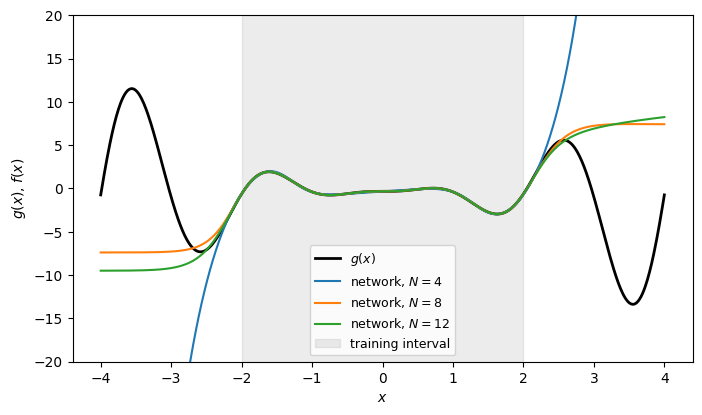

In [24]:
x_wide = np.linspace(-4, 4, 800)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x_wide, g(x_wide), "k", lw=2, label="$g(x)$")
for N in [4, 8, 12]:
    ax.plot(x_wide, model(best_theta[N], x_wide), label=f"network, $N = {N}$")
ax.axvspan(-2, 2, color="gray", alpha=0.15, label="training interval")
ax.set_ylim(-20, 20); ax.set_xlabel("$x$"); ax.set_ylabel("$g(x)$, $f(x)$"); ax.legend(fontsize=9)
plt.show()

Outside the training interval the network continues the trend of its outermost neurons and, far away, tends to a constant once all $\tanh$ saturate;
it has no information about the oscillations of $g$. The UAT is a statement about a **compact** set; the network has learned the data, not the formula
for $g(x)$. The same limitation applies whenever a network is applied to physical parameters outside its training range.
<hr/>
## 11. Summary
- One hidden layer = a weighted sum of shifted, stretched $\tanh$ steps; pairs of steps make bumps, sums of bumps approximate any continuous function.
- The UAT guarantees existence of good parameters; finding them is a non-convex minimisation of $\mathcal L(\vec\theta)$.
- Gradient-free methods need no derivatives but scale badly; finite-difference gradients cost $\mathcal O(\dim\vec\theta)$ evaluations (a number proportional to the number of parameters); backpropagation/autograd gives the exact gradient at the cost of a few evaluations of $\mathcal L$, independently of $\dim\vec\theta$.
- For small smooth problems quasi-Newton methods (BFGS, L-BFGS) are very effective; for large networks and mini-batches, first-order methods (SGD, Adam) are used.
- Different initialisations lead to different minima.
- A fitted network interpolates; it does not extrapolate.
<hr/>
## 12. Exercises

### Exercise 1 — Activation functions
Repeat the experiment of Section 7, with an additional output bias $c$, for three activations: $\tanh$, the sigmoid $1/(1+e^{-z})$ and ReLU $\max(0,z)$.
Use PyTorch with Adam (`lr=1e-2`, 1000 steps; more steps give lower losses but take longer), $N\in\{4, 8, 16\}$, and plot the final loss vs. $N$ for each activation.
Plot the ReLU fit for $N = 8$: what kind of function is it?

#### Solution

tanh     final losses for N = [4, 8, 16]: 6.5e-02, 7.2e-02, 3.1e-02


sigmoid  final losses for N = [4, 8, 16]: 1.2e-01, 1.1e-01, 4.6e-02


ReLU     final losses for N = [4, 8, 16]: 2.2e-01, 1.0e-01, 5.4e-02


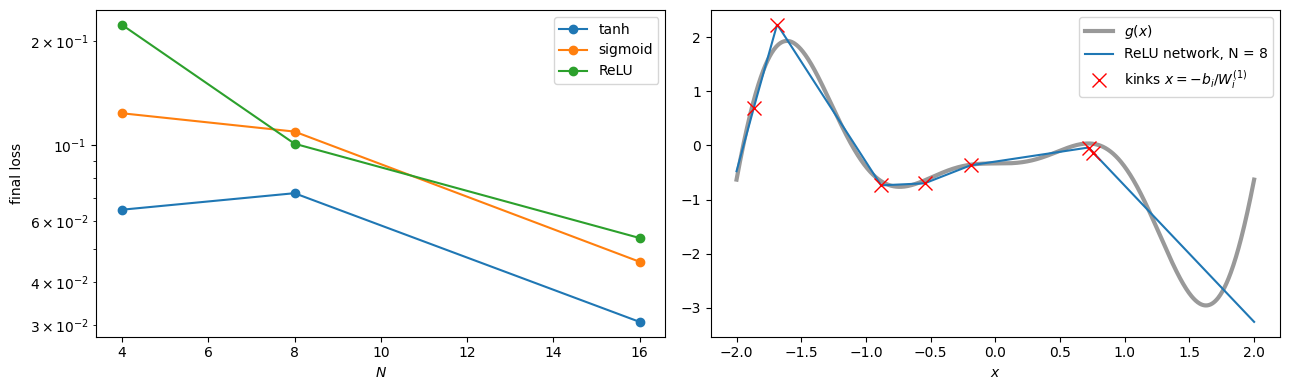

In [25]:
activations = {name: ACTIVATIONS[name] for name in ["tanh", "sigmoid", "ReLU"]}   # from Section 8

def fit_adam(N, act, n_steps=1000, lr=1e-2, seed=0):
    """Fit f(x) = sum_i W2_i act(W1_i x + b_i) + c with Adam; return the final loss and the parameters."""
    torch.manual_seed(seed)
    # the initialisation of Section 4 (input x in [-2, 2], not rescaled as in fit_uat)
    W1 = (2 * torch.randn(N)).requires_grad_()
    b = (2 * torch.randn(N)).requires_grad_()
    W2 = (torch.randn(N) / N**0.5).requires_grad_()
    c = torch.zeros(1, requires_grad=True)          # output bias: sigmoid and ReLU are not odd, a shift helps
    opt = torch.optim.Adam([W1, b, W2, c], lr=lr)
    for _ in range(n_steps):
        opt.zero_grad()
        pred = act(xt[:, None] * W1 + b) @ W2 + c
        L = torch.mean((pred - yt)**2)
        L.backward()
        opt.step()
    return L.item(), (W1, b, W2, c)

Ns_act = [4, 8, 16]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, act in activations.items():
    losses = [fit_adam(N, act)[0] for N in Ns_act]
    print(f"{name:8s} final losses for N = {Ns_act}: " + ", ".join(f"{L:.1e}" for L in losses))
    axes[0].semilogy(Ns_act, losses, "o-", label=name)
axes[0].set_xlabel("$N$"); axes[0].set_ylabel("final loss"); axes[0].legend()

# the ReLU network is piecewise linear: N kinks at x = -b_i / W1_i
_, (W1, b, W2, c) = fit_adam(8, torch.relu)
with torch.no_grad():
    xp = torch.tensor(x_plot)
    f_relu = (torch.relu(xp[:, None] * W1 + b) @ W2 + c).numpy()      # ReLU network on the dense grid
    axes[1].plot(x_plot, g(x_plot), "k", lw=3, alpha=0.4, label="$g(x)$")
    axes[1].plot(x_plot, f_relu, label="ReLU network, N = 8")
    kinks = (-b / W1).numpy()
    kinks = kinks[(kinks > -2) & (kinks < 2)]
    axes[1].plot(kinks, np.interp(kinks, x_plot, f_relu),
                 "rx", ms=10, label="kinks $x = -b_i/W^{(1)}_i$")
axes[1].legend(); axes[1].set_xlabel("$x$")
fig.tight_layout(); plt.show()
# tanh gives the lowest loss for every N. All losses (printed above) are of order 1e-2 to 1e-1, far above the BFGS
# results of Section 7: 1000 Adam steps are not enough to converge, which is also why the loss does not always
# decrease with N (tanh, N = 8 vs N = 4). The ReLU fit is piecewise linear: straight segments joined at the kinks.

### Exercise 2 — Noisy data and overfitting
Real data are noisy and scarce. Generate $K=20$ training points $y_k = g(x_k) + \xi_k$, $\xi_k\sim\mathcal N(0, \sigma_\xi^2)$ with noise standard deviation $\sigma_\xi = 0.3$, with $x_k$ uniformly random in $[-2,2]$,
and a separate **validation set** of 200 noisy points.
1. Fit networks with $N \in\{2, 4, 8, 16, 32, 64\}$ using BFGS (with the functions `loss` and `grad`, passing the data through `args=`).
   `minimize` calls `loss(theta, *args)` and `grad(theta, *args)`; so far `args` was not given and the default arguments `x=x_train, y=y_train` were used.
2. Plot the training and the validation loss vs. $N$.
3. Plot the fits for a small and for the largest $N$ and explain the result. (This is the starting point of the next lecture: *regularisation*.)

#### Solution

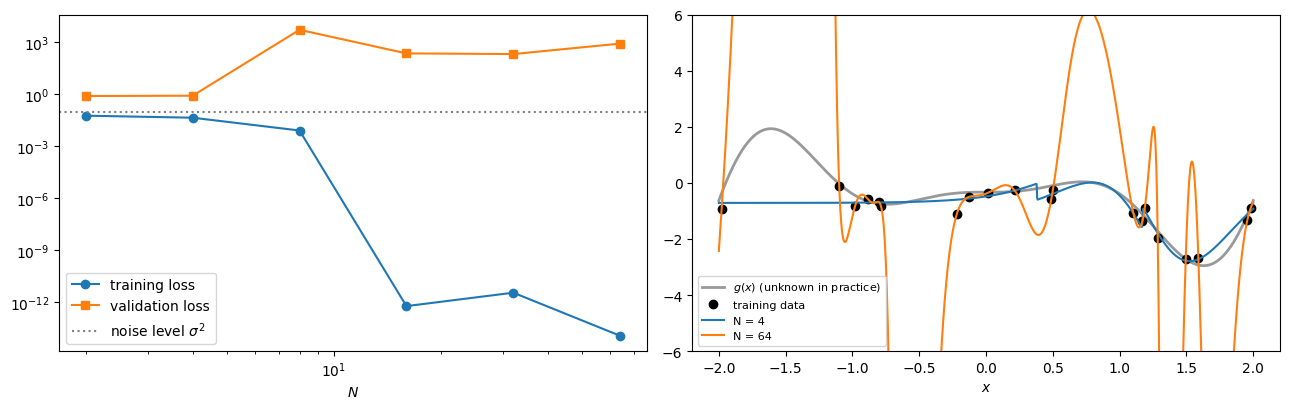

N =   2:  training loss = 5.8e-02,  validation loss = 8.0e-01
N =   4:  training loss = 4.4e-02,  validation loss = 8.3e-01
N =   8:  training loss = 8.1e-03,  validation loss = 5.4e+03
N =  16:  training loss = 5.6e-13,  validation loss = 2.3e+02
N =  32:  training loss = 3.4e-12,  validation loss = 2.1e+02
N =  64:  training loss = 1.1e-14,  validation loss = 8.6e+02
smallest validation loss at N = 2


In [26]:
rng = np.random.default_rng(7)
noise = 0.3
x_tr = np.sort(rng.uniform(-2, 2, 20)); y_tr = g(x_tr) + noise * rng.normal(size=20)
x_val = rng.uniform(-2, 2, 200);        y_val = g(x_val) + noise * rng.normal(size=200)

Ns_of = [2, 4, 8, 16, 32, 64]
train_loss, val_loss, fits = [], [], {}
for N in Ns_of:
    # best of 3 starts, judged on the TRAINING loss (the validation set must not be used for fitting).
    # At most 2000 iterations per run (for speed). The networks with N >= 16 nevertheless pass through
    # all 20 points: their training losses are of order 1e-12 or smaller.
    runs = [minimize(loss, init_theta(N, s), args=(x_tr, y_tr), jac=grad, method="BFGS",
                     options={"maxiter": 2000}) for s in range(3)]
    best = min(runs, key=lambda r: r.fun)
    fits[N] = best.x
    train_loss.append(best.fun)
    val_loss.append(loss(best.x, x_val, y_val))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].loglog(Ns_of, train_loss, "o-", label="training loss")
axes[0].loglog(Ns_of, val_loss, "s-", label="validation loss")
axes[0].axhline(noise**2, color="gray", ls=":", label=r"noise variance $0.3^2$")
axes[0].set_xlabel("$N$"); axes[0].legend()

axes[1].plot(x_plot, g(x_plot), "k", lw=2, alpha=0.4, label="$g(x)$ (unknown in practice)")
axes[1].plot(x_tr, y_tr, "o", color="k", label="training data")
for N in [4, 64]:
    axes[1].plot(x_plot, model(fits[N], x_plot), label=f"N = {N}")
axes[1].set_ylim(-6, 6); axes[1].set_xlabel("$x$"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
for N, tr, va in zip(Ns_of, train_loss, val_loss):
    print(f"N = {N:3d}:  training loss = {tr:.1e},  validation loss = {va:.1e}")
print("smallest validation loss at N =", Ns_of[int(np.argmin(val_loss))])
# The training loss decreases with N and drops far below the noise variance 0.3^2 = 0.09: a large network
# passes through the 20 noisy points and oscillates strongly between them. The validation loss is smallest for a
# small network (printed above) and becomes orders of magnitude larger for large N: overfitting.
# The validation loss is not monotonic in N: it peaks at N = 8 (5.4e+03) and is lower again for N = 16, 32 (about 2e+02).
# Even its smallest value (0.8 at N = 2) is well above the noise variance 0.09, so none of these fits reproduces g closely.

### Exercise 3 — Learning-rate scan
For $N=10$ and the common start $\vec\theta_0$, run SGD and Adam for 1000 steps with learning rates $\eta\in\{10^{-4}, 10^{-3}, \dots, 1\}$
(use `np.logspace(-4, 0, 5)`; a finer scan with `np.logspace(-4, 0, 9)` and 2000 steps takes about 3.5 times longer) and plot the final loss vs. $\eta$ (log-log). Mark runs that diverged (`nan` or `inf`).
Which optimiser is less sensitive to the choice of $\eta$?

#### Solution

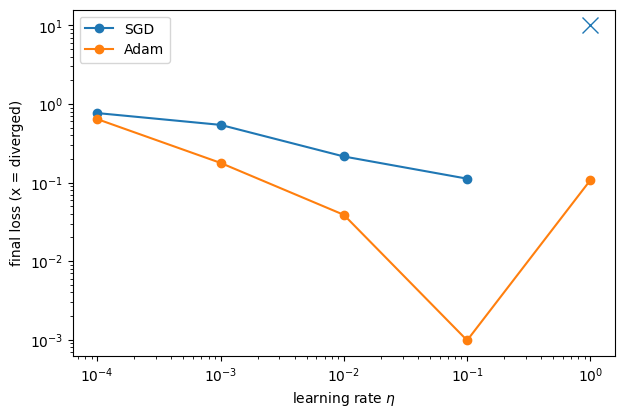

In [27]:
lrs = np.logspace(-4, 0, 5)          # 5 values and 1000 steps keep the cell fast; 9 values and 2000 steps give a finer picture
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, opt_name in enumerate(["SGD", "Adam"]):
    finals = np.array([run_torch(opt_name, 1000, lr=lr)["final_loss"] for lr in lrs])
    ok = np.isfinite(finals) & (finals < 1e3)           # diverged: nan/inf, or far above the initial loss of about 1
    # ~ok is the element-wise NOT of the boolean array: True for the diverged runs; np.full(n, 1e1) is an array of n values 10
    ax.loglog(lrs[ok], finals[ok], "o-", color=f"C{i}", label=opt_name)
    ax.loglog(lrs[~ok], np.full((~ok).sum(), 1e1), "x", color=f"C{i}", ms=12)   # crosses at an arbitrary height 10
ax.set_xlabel(r"learning rate $\eta$"); ax.set_ylabel("final loss (x = diverged)")
ax.legend(); plt.show()
# SGD converges slowly for small eta and diverges once eta exceeds a threshold (the crosses).
# Adam divides each step by the square root of a running average of the squared gradient, so its step length is
# about eta independently of the size of the gradient; it does not diverge in the scanned range and reaches much
# lower losses, with an optimum at an intermediate eta.

### Exercise 4 — A network as a surrogate for a quantum calculation
The ground-state energy $E_0(\kappa)$ of the double well $V = \tfrac12x^2 + \kappa e^{-x^2/2}$ can be computed by exact diagonalisation of the finite-difference Hamiltonian.
Suppose each diagonalisation were expensive and we could afford only **12** of them.
1. Compute $E_0(\kappa_j)$ for 12 randomly chosen $\kappa_j\in[0, 12]$ (the first lines of the solution build the data; you may copy them).
2. Fit a one-hidden-layer network ($N=8$, $\tanh$, with output bias) to these 12 points, in PyTorch with L-BFGS. Rescale the input to $[-1,1]$ first.
3. Compare the network with the exact $E_0(\kappa)$ on a fine grid of 100 points.
4. Use autograd on the **network** to get $dE_0/d\kappa$ and compare with the exact derivative (Hellmann–Feynman).
   Is the derivative of a good fit also a good approximation of the derivative?

#### Solution

training loss: 6.09e-07


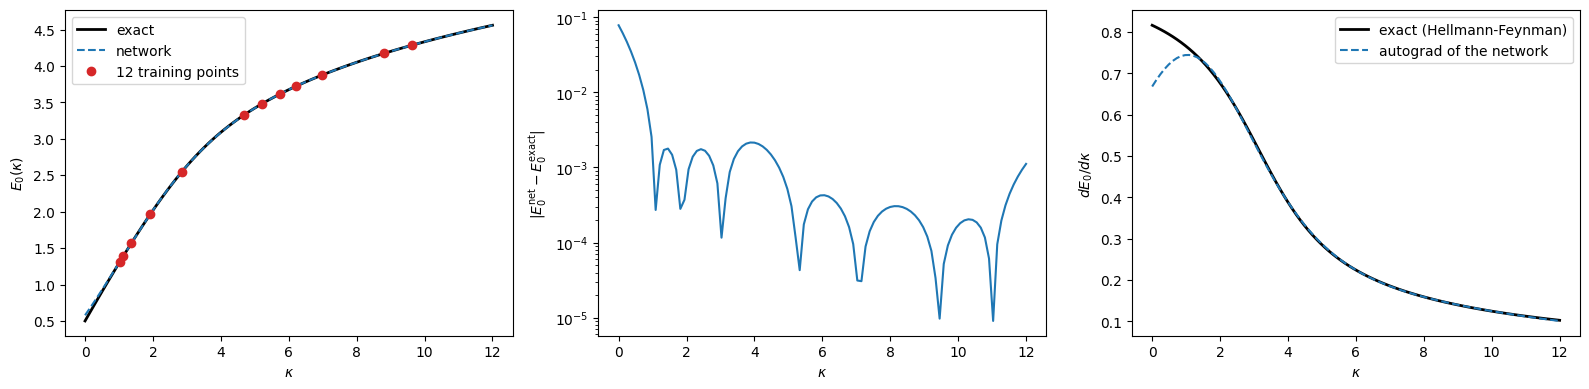

training kappa from 1.03 to 9.62
max error of E0 :  inside 2.1e-03,  outside 7.8e-02
max error of dE0:  inside 1.5e-02,  outside 1.5e-01


In [28]:
xg = np.linspace(-6, 6, 300); dxg = xg[1] - xg[0]
H_kin = -0.5 / dxg**2 * (np.diag(np.ones(299), 1) - 2 * np.eye(300) + np.diag(np.ones(299), -1))
def E0_and_dE0(kappa):
    """Exact ground-state energy and its derivative (Hellmann-Feynman) for barrier height kappa."""
    E, psi = np.linalg.eigh(H_kin + np.diag(0.5 * xg**2 + kappa * np.exp(-xg**2 / 2)))
    # Hellmann-Feynman: dE0/dkappa = <psi0| dH/dkappa |psi0> with dH/dkappa = exp(-x^2/2).
    # eigh normalises sum(psi**2) = 1, so the expectation value is a plain sum (no factor dx).
    return E[0], np.sum(psi[:, 0]**2 * np.exp(-xg**2 / 2))

# 1) the 12 "expensive" data points and a fine reference grid
k_train = np.sort(np.random.default_rng(3).uniform(0, 12, 12))     # 12 random, non-equidistant points
E_train = np.array([E0_and_dE0(k)[0] for k in k_train])
k_fine = np.linspace(0, 12, 100)
# the list of 100 pairs (E0, dE0) becomes an array of shape (100, 2); .T gives shape (2, 100), whose two rows are unpacked
E_fine, dE_fine = np.array([E0_and_dE0(k) for k in k_fine]).T

# 2) network with output bias; input rescaled from [0, 12] to [-1, 1]
to_unit = lambda k: (k - 6.0) / 6.0
torch.manual_seed(0)
N = 8
# standard deviation 1 (an arbitrary choice): on the rescaled input [-1, 1] it already places the steps inside the interval
W1, b, W2 = torch.randn(N, requires_grad=True), torch.randn(N, requires_grad=True), torch.randn(N, requires_grad=True)
c = torch.tensor([E_train.mean()], requires_grad=True)
net = lambda k: torch.tanh(to_unit(k)[:, None] * W1 + b) @ W2 + c

kt, Et = torch.tensor(k_train), torch.tensor(E_train)
opt = torch.optim.LBFGS([W1, b, W2, c], lr=1, max_iter=50, line_search_fn="strong_wolfe")
def closure():
    opt.zero_grad()
    L = torch.mean((net(kt) - Et)**2)
    L.backward()
    return L
for _ in range(10):          # with 25 parameters and 12 points the loss stops changing after 5 outer steps
    L = opt.step(closure)
print(f"training loss: {L.item():.2e}")

# 3) and 4) prediction and its derivative on the fine grid (autograd w.r.t. the INPUT kappa)
kf = torch.tensor(k_fine, requires_grad=True)
E_pred = net(kf)
# E_pred[j] depends only on kf[j], so the gradient of the SUM w.r.t. kf is the vector of derivatives dE_pred[j]/dkappa_j.
# torch.autograd.grad returns a tuple (one entry per input); (dE_pred,) = ... unpacks its single element.
(dE_pred,) = torch.autograd.grad(E_pred.sum(), kf)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_fine, E_fine, "k", lw=2, label="exact")
axes[0].plot(k_fine, E_pred.detach(), "--", label="network")
axes[0].plot(k_train, E_train, "o", color="C3", label="12 training points")
axes[0].set_ylabel(r"$E_0(\kappa)$"); axes[0].legend()
axes[1].semilogy(k_fine, np.abs(E_pred.detach().numpy() - E_fine))
axes[1].set_ylabel(r"$|E_0^{\rm net} - E_0^{\rm exact}|$")
axes[2].plot(k_fine, dE_fine, "k", lw=2, label="exact (Hellmann-Feynman)")
axes[2].plot(k_fine, dE_pred, "--", label="autograd of the network")
axes[2].set_ylabel(r"$dE_0/d\kappa$"); axes[2].legend()
for ax in axes: ax.set_xlabel(r"$\kappa$")
fig.tight_layout(); plt.show()
inside = (k_fine >= k_train.min()) & (k_fine <= k_train.max())     # between the smallest and largest training kappa
err_E, err_dE = np.abs(E_pred.detach().numpy() - E_fine), np.abs(dE_pred.numpy() - dE_fine)
print(f"training kappa from {k_train.min():.2f} to {k_train.max():.2f}")
print(f"max error of E0 :  inside {err_E[inside].max():.1e},  outside {err_E[~inside].max():.1e}")
print(f"max error of dE0:  inside {err_dE[inside].max():.1e},  outside {err_dE[~inside].max():.1e}")
# Between the smallest and largest training kappa (interpolation) the errors are much smaller than outside the
# sampled range (extrapolation, see Section 10). Inside, the derivative is less accurate than the energy itself:
# the loss contains only values of E0, nothing constrains the slope directly. The network has 25 parameters
# for 12 data points, so it can pass through all of them; the fit is nevertheless smooth here because E0(kappa)
# itself is smooth. (Adding the Hellmann-Feynman derivatives to the loss is known as Sobolev training.)

### Exercise 5 (advanced) — Two dimensions
The UAT holds in any dimension. Fit $g(x,y) = \sin(2x)\cos(y) e^{-(x^2+y^2)/4}$ on $[-3,3]^2$ (a $30\times30$ grid of training points)
with `nn.Sequential(nn.Linear(2, N), nn.Tanh(), nn.Linear(N, 1))` for $N = 8, 32, 128$, using Adam (`lr=1e-2`, 1500 steps; kept small for speed, 3000 or more steps give smaller errors).
Here `nn.Linear(n_in, n_out)` is the affine map $\mathbf W\mathbf x + \mathbf b$ from $n_{\rm in}$ to $n_{\rm out}$ components (with trainable $\mathbf W$ and $\mathbf b$), and `nn.Sequential` chains the layers, applying them one after another.
Show the target, the fit and the error as images (`imshow`), one row per $N$.
The first lines of the solution build the data (you may copy them): `torch.meshgrid(xs, xs, indexing="xy")` returns two $30\times30$ arrays `X`, `Y` with the $x$ and $y$ coordinates of all grid points
(with `"xy"` the rows correspond to $y$, the layout that `imshow` expects), and `reshape(-1)` flattens them into lists of 900 points.

#### Solution

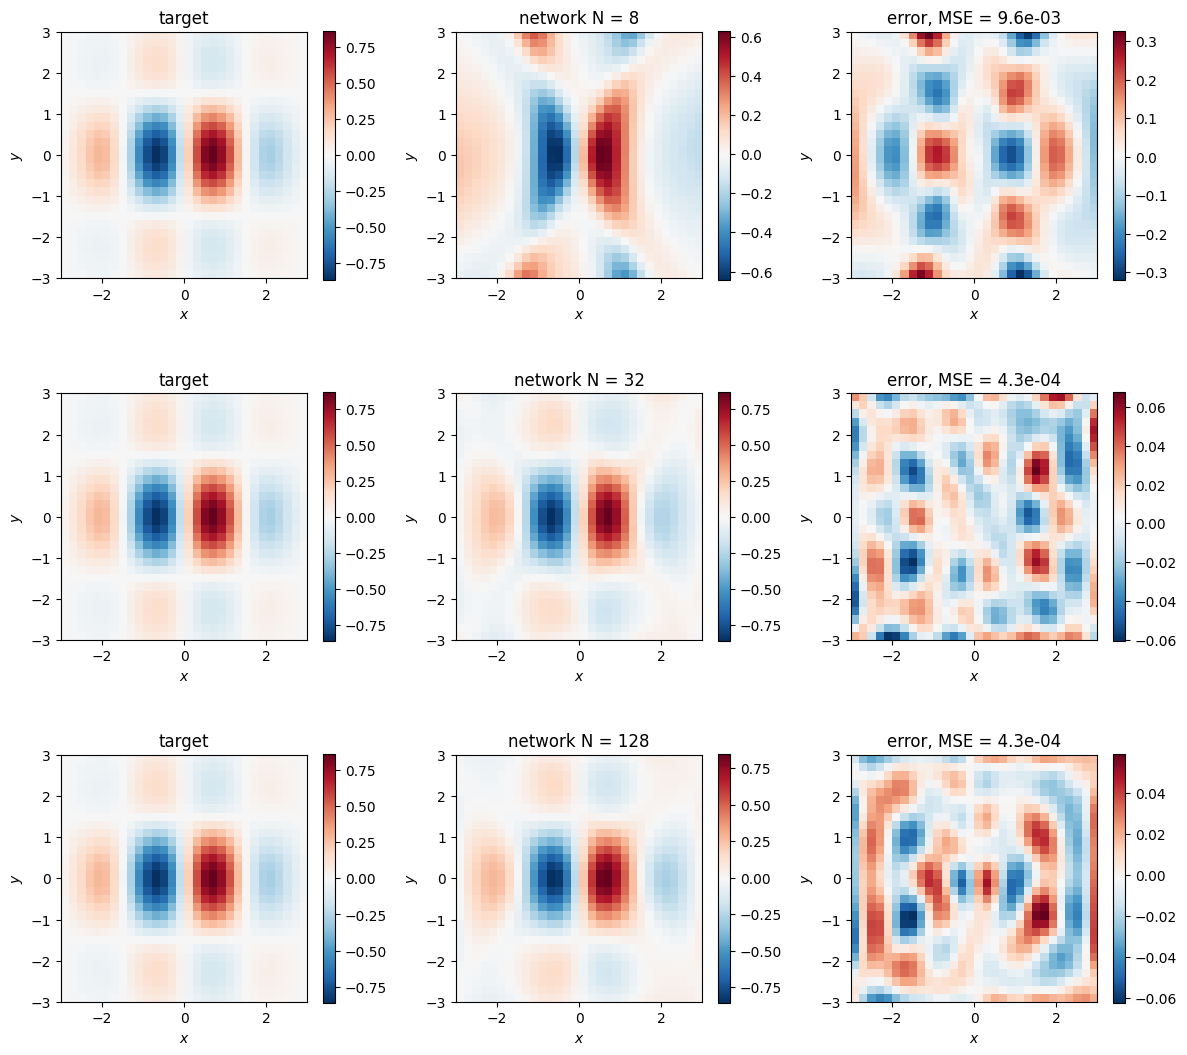

In [29]:
import torch.nn as nn
n_grid = 30
xs = torch.linspace(-3, 3, n_grid)
X, Y = torch.meshgrid(xs, xs, indexing="xy")
G = torch.sin(2 * X) * torch.cos(Y) * torch.exp(-(X**2 + Y**2) / 4)
inputs = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)   # shape (900, 2): each row is a point (x, y)
targets = G.reshape(-1, 1)                                    # shape (900, 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, N in enumerate([8, 32, 128]):
    torch.manual_seed(0)
    # nn.Linear creates its weights and biases with PyTorch's default random initialisation (scaled by 1/sqrt(n_in))
    net2d = nn.Sequential(nn.Linear(2, N), nn.Tanh(), nn.Linear(N, 1))
    opt = torch.optim.Adam(net2d.parameters(), lr=1e-2)
    for _ in range(1500):
        opt.zero_grad()
        L = torch.mean((net2d(inputs) - targets)**2)
        L.backward()
        opt.step()
    with torch.no_grad():
        F_net = net2d(inputs).reshape(n_grid, n_grid)
    for ax, img, title in zip(axes[row], [G, F_net, F_net - G],
                              ["target", f"network N = {N}", f"error, MSE = {L.item():.1e}"]):
        im = ax.imshow(img, origin="lower", extent=[-3, 3, -3, 3], cmap="RdBu_r")
        fig.colorbar(im, ax=ax, shrink=0.8)
        ax.set_title(title); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
fig.tight_layout(); plt.show()
# The error decreases from N = 8 to N = 32; beyond that the result is limited by the 1500 Adam steps, not by N
# (N = 32 and N = 128 give the same MSE).